# Proyecto final: pronóstico semanal de dengue

En este trabajo buscamos pronosticar los casos de dengue de la semana **t+4** en cinco municipios del Valle del Cauca. Comparamos historias de **12, 16 y 20 semanas** para estudiar cuánto aporta la información de los meses anteriores.

Los puntos 1 al 12 preparan los datos. Del 13 al 19 construimos la comparación de modelos, revisamos la validación y discutimos los resultados. El punto 20 reúne la evaluación y el análisis final; permanece desactivado mientras continuamos explorando arquitecturas.

El entrenamiento comprende 2007–2021 y la validación, 2022–2023. Los datos de 2024–2025 se preparan por separado para evaluación. Ese último periodo ya se consultó en etapas anteriores, aunque no se volvió a utilizar en la exploración actual. Por eso, sus resultados posteriores deberán interpretarse teniendo en cuenta ese antecedente.

Para ejecutar el notebook usamos el entorno `.venv` del proyecto. Los modelos y resultados anteriores siguen guardados, junto con una copia del notebook anterior a la reorganización.


## 1. Verificar el entorno

Primero comprobamos qué versión de Python estamos usando y desde qué carpeta se ejecuta el notebook. El intérprete debe pertenecer al entorno `.venv` y la carpeta del proyecto debe contener `DataRaw`.


In [2]:
from pathlib import Path
import sys

PROYECTO = Path.cwd()
assert (PROYECTO / 'DataRaw').is_dir(), 'Abre Jupyter desde la carpeta ProyectoFinal.'
assert Path(sys.prefix).resolve() == (PROYECTO / '.venv').resolve(), 'Selecciona el kernel Python (ProyectoFinal).'
print(f'Python: {sys.version.split()[0]}')
print(f'Intérprete: {sys.executable}')
print(f'Carpeta del proyecto: {PROYECTO}')

Python: 3.13.3
Intérprete: C:\Users\user\Documents\FelipeFolder\UdeLosAndes\Maestria\ProyectoFinal\.venv\Scripts\python.exe
Carpeta del proyecto: C:\Users\user\Documents\FelipeFolder\UdeLosAndes\Maestria\ProyectoFinal


## 2. Librerías del proyecto

La lectura y el análisis de datos utilizan `pandas`, `python-calamine` y `matplotlib`. Las dependencias del proyecto están registradas en `requirements.txt` y sus versiones instaladas, en `requirements-lock.txt`.

Si hace falta instalar otra librería desde el notebook, podemos usar `%pip install nombre_libreria`. Las instrucciones para preparar el entorno están en README.md.


In [3]:
# pandas y python-calamine ya están instalados en .venv.
# Para instalar otra librería: %pip install nombre_libreria

## 3. Revisar los archivos de dengue

Trabajamos con los CSV anuales de `DataRaw`, con nombres como `Datos_AAAA_210.csv`. Contienen únicamente los registros del Valle del Cauca y las cinco columnas que usa el proyecto: `COD_DPTO_O`, `COD_MUN_O`, `SEMANA`, `ANO` e `INI_SIN`.

Los Excel completos de los 19 años se conservan en `DataRawOriginal`. La reducción mantiene todos los municipios del departamento, las fechas faltantes y las filas repetidas; la limpieza y la elección de municipios siguen en los pasos posteriores.

La siguiente celda revisa los archivos de 2007–2025. La primera lectura utiliza 2007–2023; los años 2024–2025 se preparan por separado. La función de lectura prefiere los CSV y también admite Excel si se necesita trabajar con ese formato.


In [4]:
DATOS_RAW = PROYECTO / 'DataRaw'
import pandas as pd
from datos_dengue import (
    COLUMNAS_CASOS, DEPARTAMENTO, codigo_departamento,
    ruta_archivo_dengue, leer_archivo_dengue,
)

ANOS = range(2007, 2026)
ANOS_ENTRENAMIENTO = range(2007, 2022)
ANOS_VALIDACION = range(2022, 2024)
ANOS_TEST = range(2024, 2026)
ANOS_ANALISIS = range(2007, 2024)
COLUMNAS = COLUMNAS_CASOS.copy()
archivos_dengue = [ruta_archivo_dengue(ano, DATOS_RAW) for ano in ANOS]

print(f'Archivos encontrados: {len(archivos_dengue)} (2007–2025). Departamento: {DEPARTAMENTO}.')
print('Se utilizan los CSV reducidos de DataRaw. Los Excel completos están en DataRawOriginal.')
pd.DataFrame({
    'ANO_ARCHIVO': list(ANOS),
    'ARCHIVO': [archivo.name for archivo in archivos_dengue],
    'TAMANO_MB': [round(archivo.stat().st_size / 1024**2, 2) for archivo in archivos_dengue],
})


Archivos encontrados: 19 (2007–2025). Departamento: 76.
Se utilizan los CSV reducidos de DataRaw. Los Excel completos están en DataRawOriginal.


,ANO_ARCHIVO,ARCHIVO,TAMANO_MB
0,2007,Datos_2007_210.csv,0.02
1,2008,Datos_2008_210.csv,0.08
2,2009,Datos_2009_210.csv,0.40
3,2010,Datos_2010_210.csv,0.76
4,2011,Datos_2011_210.csv,0.10
5,2012,Datos_2012_210.csv,0.12
6,2013,Datos_2013_210.csv,0.87
7,2014,Datos_2014_210.csv,0.41
8,2015,Datos_2015_210.csv,0.79
9,2016,Datos_2016_210.csv,1.02


## 4. Leer y unir los registros de 2007–2023

Leemos los archivos reducidos del Valle del Cauca de 2007–2023 y los reunimos en `df_dengue`. Antes de unirlos, excluimos las filas sin fecha de inicio de síntomas (`INI_SIN`), siguiendo el criterio de limpieza del proyecto. Las filas con campos coincidentes se mantienen.

Los códigos de departamento y municipio se guardan como texto para conservar los ceros iniciales. `ANO` y `SEMANA` se leen como enteros y `INI_SIN` conserva el texto del archivo. El conteo posterior utiliza el año y la semana registrados; no recalculamos la semana a partir de la fecha de síntomas.

Los mensajes de carga muestran cuántas filas se leyeron, cuántas se descartaron y cuántas quedaron en cada archivo.


In [5]:
from time import perf_counter

inicio = perf_counter()
partes = []
resumen_archivos = []
print('Se eliminarán las filas sin INI_SIN antes de unir, agrupar y analizar los datos.', flush=True)

for ano_archivo, archivo in zip(ANOS, archivos_dengue):
    if ano_archivo not in ANOS_ANALISIS:
        continue  # No abrir los archivos reservados para test (2024 y 2025).
    print(f'Leyendo {archivo.name}...', flush=True)
    try:
        datos_ano = leer_archivo_dengue(archivo, COLUMNAS)
        datos_ano = datos_ano.loc[
            codigo_departamento(datos_ano['COD_DPTO_O']).eq(DEPARTAMENTO).fillna(False)
        ].copy()
        # Unificar nulos, textos vacíos y espacios antes de contar las exclusiones.
        datos_ano['INI_SIN'] = datos_ano['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
        casos_originales = len(datos_ano)
        eliminados_ini_sin = int(datos_ano['INI_SIN'].isna().sum())
        datos_ano = datos_ano.dropna(subset=['INI_SIN']).reset_index(drop=True)
        for columna in ['SEMANA', 'ANO']:
            datos_ano[columna] = pd.to_numeric(datos_ano[columna], errors='raise').astype('Int64')
    except Exception as error:
        raise RuntimeError(f'No se pudo cargar {archivo.name}: {error}') from error

    resumen_archivos.append({
        'ANO_ARCHIVO': ano_archivo,
        'ARCHIVO': archivo.name,
        'CASOS_ORIGINALES': casos_originales,
        'FILAS_ELIMINADAS_INI_SIN': eliminados_ini_sin,
        'CASOS': len(datos_ano),
        'ANO_FALTANTE': int(datos_ano['ANO'].isna().sum()),
        'ANO_DISTINTO_AL_ARCHIVO': int(datos_ano['ANO'].ne(ano_archivo).fillna(False).sum()),
    })
    partes.append(datos_ano)
    print(f'  {len(datos_ano):,} casos conservados; {eliminados_ini_sin:,} filas eliminadas.', flush=True)

df_dengue = pd.concat(partes, ignore_index=True).loc[:, COLUMNAS]
resumen_carga = pd.DataFrame(resumen_archivos)
filas_antes_limpieza = int(resumen_carga['CASOS_ORIGINALES'].sum())
filas_eliminadas = int(resumen_carga['FILAS_ELIMINADAS_INI_SIN'].sum())
assert len(df_dengue) == resumen_carga['CASOS'].sum(), 'El total unido no coincide con los archivos.'
assert len(df_dengue) == filas_antes_limpieza - filas_eliminadas
assert df_dengue['INI_SIN'].notna().all(), 'El DataFrame final contiene INI_SIN faltantes.'
assert df_dengue['ANO'].isin(ANOS_ANALISIS).all(), 'La carga de desarrollo contiene datos fuera de 2007-2023.'
del partes, datos_ano

print(f'\nFilas eliminadas por INI_SIN faltante: {filas_eliminadas:,}')
print(f'Total limpio: {len(df_dengue):,} casos y {df_dengue.shape[1]} columnas.')
print(f'Tiempo de carga: {perf_counter() - inicio:.1f} segundos.')
df_dengue.head()

Se eliminarán las filas sin INI_SIN antes de unir, agrupar y analizar los datos.


Leyendo Datos_2007_210.csv...


  577 casos conservados; 0 filas eliminadas.


Leyendo Datos_2008_210.csv...


  1,909 casos conservados; 0 filas eliminadas.


Leyendo Datos_2009_210.csv...


... (27 outputs left out)

Leyendo Datos_2023_210.csv...


  23,983 casos conservados; 0 filas eliminadas.



Filas eliminadas por INI_SIN faltante: 12
Total limpio: 194,409 casos y 5 columnas.
Tiempo de carga: 0.6 segundos.


,COD_DPTO_O,COD_MUN_O,SEMANA,ANO,INI_SIN
0,76,147,26,2007,22/06/2007 12:00:00 a. m.
1,76,109,5,2007,12/01/2007 12:00:00 a. m.
2,76,001,23,2007,31/05/2007 12:00:00 a. m.
3,76,001,16,2007,18/04/2007 12:00:00 a. m.
4,76,036,30,2007,18/07/2007 12:00:00 a. m.


### 4.1. Comprobar las filas sin fecha de inicio de síntomas

La lectura anterior ya excluye las filas sin `INI_SIN`. Esta celda permite aplicar la misma limpieza al DataFrame que esté en memoria, sin volver a leer los archivos anuales. Considera faltantes tanto los valores nulos como los textos vacíos o formados solo por espacios.


In [6]:
# ELIMINAR FILAS SIN INI_SIN DEL DATAFRAME ACTUAL
# Convertir textos vacios o con solo espacios a valores faltantes.
df_dengue['INI_SIN'] = df_dengue['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)

# Eliminar directamente las filas cuyo INI_SIN es faltante.
df_dengue.dropna(subset=['INI_SIN'], inplace=True)
df_dengue.reset_index(drop=True, inplace=True)

print(f"Faltantes en INI_SIN: {df_dengue['INI_SIN'].isna().sum()}")
print(f'Casos restantes: {len(df_dengue):,}')

Faltantes en INI_SIN: 0
Casos restantes: 194,409


## 5. Revisar los datos después de la limpieza

La tabla `resumen_carga` reúne, por archivo, las filas originales, las eliminadas por falta de `INI_SIN` y los casos conservados. También señala si el valor de `ANO` difiere del año indicado en el nombre del archivo. Esos valores originales no se cambian.


In [7]:
resumen_carga

,ANO_ARCHIVO,ARCHIVO,CASOS_ORIGINALES,FILAS_ELIMINADAS_INI_SIN,CASOS,ANO_FALTANTE,ANO_DISTINTO_AL_ARCHIVO
0,2007,Datos_2007_210.csv,577,0,577,0,0
1,2008,Datos_2008_210.csv,1909,0,1909,0,0
2,2009,Datos_2009_210.csv,10139,0,10139,0,0
3,2010,Datos_2010_210.csv,19079,4,19075,0,0
4,2011,Datos_2011_210.csv,2567,1,2566,0,0
5,2012,Datos_2012_210.csv,2985,0,2985,0,0
6,2013,Datos_2013_210.csv,21963,5,21958,0,0
7,2014,Datos_2014_210.csv,10190,0,10190,0,0
8,2015,Datos_2015_210.csv,19818,0,19818,0,0
9,2016,Datos_2016_210.csv,25730,2,25728,0,0


### 5.1. Revisar los valores faltantes

La tabla siguiente muestra los faltantes que quedan en `df_dengue`. Como la limpieza ya se aplicó, `INI_SIN` debe tener cero valores faltantes. Las filas descartadas se contabilizan en `resumen_carga` y ya no forman parte de este DataFrame.


In [8]:
print(f'Filas eliminadas durante la carga por INI_SIN faltante: {filas_eliminadas:,}')
print(f'Casos disponibles para agrupar y analizar: {len(df_dengue):,}')
assert df_dengue['INI_SIN'].notna().all(), 'Ejecuta de nuevo la celda de lectura y limpieza.'
pd.DataFrame({
    'TIPO': df_dengue.dtypes.astype(str),
    'VALORES_FALTANTES_DATOS_LIMPIOS': df_dengue.isna().sum(),
})

Filas eliminadas durante la carga por INI_SIN faltante: 12
Casos disponibles para agrupar y analizar: 194,409


,TIPO,VALORES_FALTANTES_DATOS_LIMPIOS
COD_DPTO_O,string,0
COD_MUN_O,string,0
SEMANA,Int64,0
ANO,Int64,0
INI_SIN,string,0


In [9]:
df_dengue.groupby('ANO', dropna=False).size().rename('CASOS').to_frame()

,CASOS
ANO,
2007,577
2008,1909
2009,10139
2010,19075
2011,2566
2012,2985
2013,21958
2014,10190
2015,19818


## 6. Explorar los datos de desarrollo

### 6.1. Separar los periodos de trabajo

Dividimos la serie en orden cronológico:

| Conjunto | Periodo | Uso |
| --- | --- | --- |
| Entrenamiento | 2007–2021 | Ajustar las transformaciones y entrenar los modelos. |
| Validación | 2022–2023 | Comparar historias, arquitecturas y configuraciones. |
| Evaluación o test | 2024–2025 | Revisar el modelo al cerrar la selección. |

`df_analisis` reúne entrenamiento y validación para las tablas y gráficas de esta parte. `df_entrenamiento` y `df_validacion` conservan los periodos separados. Los pasos siguientes preparan también el archivo de evaluación, pero la comparación actual de modelos utiliza únicamente entrenamiento y validación.


In [10]:
# Periodos cronologicos: el test de 2024-2025 permanece reservado.
ANOS_ENTRENAMIENTO = range(2007, 2022)
ANOS_VALIDACION = range(2022, 2024)
ANOS_TEST = range(2024, 2026)
ANOS_ANALISIS = range(2007, 2024)

df_analisis = df_dengue.loc[df_dengue['ANO'].isin(ANOS_ANALISIS)].copy()
df_entrenamiento = df_analisis.loc[df_analisis['ANO'].isin(ANOS_ENTRENAMIENTO)].copy()
df_validacion = df_analisis.loc[df_analisis['ANO'].isin(ANOS_VALIDACION)].copy()

assert not df_analisis.empty, 'No hay datos de 2007-2023 para analizar.'
assert df_analisis['ANO'].le(2023).all(), 'El analisis contiene datos de test.'
assert len(df_entrenamiento) + len(df_validacion) == len(df_analisis)
print('Analisis limitado a 2007-2023. Test 2024-2025 reservado para la evaluacion final.')
pd.DataFrame({
    'CONJUNTO': ['Entrenamiento', 'Validacion'],
    'PERIODO': ['2007-2021', '2022-2023'],
    'CASOS': [len(df_entrenamiento), len(df_validacion)],
})

Analisis limitado a 2007-2023. Test 2024-2025 reservado para la evaluacion final.


,CONJUNTO,PERIODO,CASOS
0,Entrenamiento,2007-2021,166210
1,Validacion,2022-2023,28199


### 6.2. Observar la evolución anual del Valle del Cauca

Contamos los registros de `df_analisis` por año durante 2007–2023. Como `DataRaw` ya contiene únicamente el departamento 76, la gráfica muestra solo Valle del Cauca. Las combinaciones sin registros aparecen con cero.


In [11]:
# Contar los casos por departamento y año.
assert df_analisis['INI_SIN'].notna().all(), 'Ejecuta primero la celda de limpieza de INI_SIN.'
casos_departamento_ano = (
    df_analisis.groupby(['COD_DPTO_O', 'ANO'], dropna=False)
    .size()
    .unstack('ANO', fill_value=0)
    .reindex(columns=ANOS_ANALISIS, fill_value=0)
    .sort_index()
)
casos_departamento_ano.index.name = 'COD_DPTO_O'
casos_departamento_ano.columns.name = 'ANO'
casos_departamento_ano

ANO,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
COD_DPTO_O,,,,,,,,,,,,,,,,,
76,577,1909,10139,19075,2566,2985,21958,10190,19818,25728,4859,2284,7378,28300,8444,4216,23983


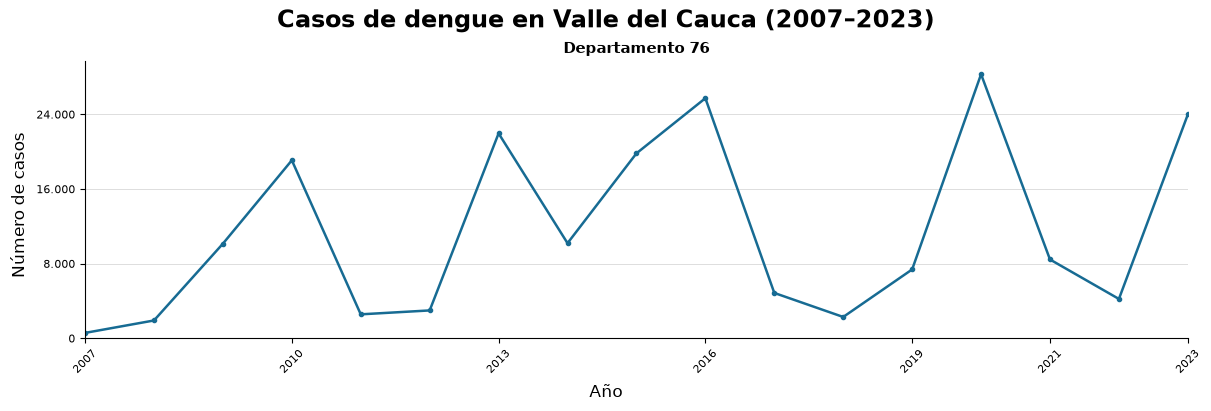

In [12]:
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

if casos_departamento_ano.empty:
    raise ValueError('No hay casos disponibles para graficar.')

departamentos = casos_departamento_ano.index.tolist()
anos_grafica = casos_departamento_ano.columns.to_numpy(dtype=int)
n_columnas = min(4, len(departamentos))
n_filas = math.ceil(len(departamentos) / n_columnas)
fig, ejes = plt.subplots(
    n_filas, n_columnas,
    figsize=(12 if n_columnas == 1 else 16, (4 if n_columnas == 1 else 2.8) * n_filas),
    squeeze=False,
    layout='constrained',
)
formato_casos = FuncFormatter(lambda valor, _: f'{valor:,.0f}'.replace(',', '.'))

for eje, departamento in zip(ejes.flat, departamentos):
    serie = casos_departamento_ano.loc[departamento]
    eje.plot(anos_grafica, serie.to_numpy(), color='#176B93', marker='o', markersize=3, linewidth=1.8)
    eje.set_title(f'Departamento {departamento}', fontsize=11, fontweight='bold')
    eje.set_xlim(2007, 2023)
    eje.set_ylim(bottom=0)
    eje.set_xticks([2007, 2010, 2013, 2016, 2019, 2021, 2023])
    eje.tick_params(axis='x', labelrotation=45, labelsize=8)
    eje.tick_params(axis='y', labelsize=8)
    eje.yaxis.set_major_locator(MaxNLocator(nbins=4, integer=True))
    eje.yaxis.set_major_formatter(formato_casos)
    eje.grid(axis='y', color='#DDDDDD', linewidth=0.7)
    eje.spines[['top', 'right']].set_visible(False)

for eje in list(ejes.flat)[len(departamentos):]:
    eje.set_visible(False)

fig.suptitle('Casos de dengue en Valle del Cauca (2007–2023)', fontsize=17, fontweight='bold')
fig.supxlabel('Año', fontsize=12)
fig.supylabel('Número de casos', fontsize=12)
plt.show()

### 6.3. Departamento de trabajo: Valle del Cauca

El departamento elegido para el proyecto es **Valle del Cauca, código 76**. Los archivos de trabajo ya están filtrados a ese departamento. La gráfica anterior describe su evolución; con esta versión reducida no comparamos el volumen de casos entre departamentos.


## 7. Asignar los nombres de los municipios

Usamos `MunicipiosValledelCauca.csv` para agregar el nombre del municipio a los registros del departamento 76. Los códigos se conservan como texto: por ejemplo, `001` corresponde a Cali y no debe convertirse en `1`. El valor `="001"` del catálogo se interpreta como el texto `001`.

Aplicamos el mismo catálogo a los tres periodos. En esta primera revisión mantenemos las filas cuyo código no encuentra correspondencia y contamos cuántas hay en cada conjunto. El punto 8 las elimina de las tablas de trabajo.

La columna `COD_MUN_O_ORIGINAL` guarda el código tal como se leyó. Los archivos originales se mantienen sin cambios.


In [13]:
# Leer el catálogo como texto: nunca convertir los códigos a enteros.
catalogo_municipios = pd.read_csv(
    PROYECTO / 'MunicipiosValledelCauca.csv',
    sep=',', encoding='utf-8-sig', dtype='string', keep_default_na=False,
)

def normalizar_codigo_texto(serie, ancho):
    return (
        serie.astype('string').str.strip()
        .str.replace(r'^="([^"]*)"$', r'\1', regex=True)
        .replace('', pd.NA)
        .str.zfill(ancho)
    )

catalogo_municipios['CODIGO_DEPARTAMENTO'] = normalizar_codigo_texto(
    catalogo_municipios['CODIGO_DEPARTAMENTO'], 2
)
catalogo_municipios['CODIGO_MUNICIPIO'] = normalizar_codigo_texto(
    catalogo_municipios['CODIGO_MUNICIPIO'], 3
)
catalogo_municipios['MUNICIPIO'] = catalogo_municipios['MUNICIPIO'].str.strip()
catalogo_valle = catalogo_municipios.loc[
    catalogo_municipios['CODIGO_DEPARTAMENTO'].eq('76')
].copy()
assert not catalogo_valle.empty, 'El catálogo no contiene municipios del departamento 76.'
assert catalogo_valle['CODIGO_MUNICIPIO'].str.fullmatch(r'\d{3}').fillna(False).all(), 'Hay códigos de municipio inválidos en el CSV.'
assert not catalogo_valle['CODIGO_MUNICIPIO'].duplicated().any(), 'Hay códigos de municipio repetidos en el CSV.'
assert catalogo_valle['MUNICIPIO'].ne('').all(), 'Hay nombres de municipio vacíos en el CSV.'
municipios_por_codigo = catalogo_valle.set_index('CODIGO_MUNICIPIO')['MUNICIPIO']
print(f'Municipios disponibles en el catálogo: {len(catalogo_valle)}')
catalogo_valle[['CODIGO_DEPARTAMENTO', 'CODIGO_MUNICIPIO', 'MUNICIPIO']]

Municipios disponibles en el catálogo: 42


,CODIGO_DEPARTAMENTO,CODIGO_MUNICIPIO,MUNICIPIO
0,76,001,CALI
1,76,020,ALCALA
2,76,036,ANDALUCIA
3,76,041,ANSERMANUEVO
4,76,054,ARGELIA
5,76,100,BOLIVAR
6,76,109,BUENAVENTURA
7,76,111,GUADALAJARA DE BUGA
8,76,113,BUGALAGRANDE
9,76,122,CAICEDONIA


In [14]:
def asignar_municipio_valle(datos):
    resultado = datos.copy()
    if 'COD_MUN_O_ORIGINAL' not in resultado.columns:
        resultado['COD_MUN_O_ORIGINAL'] = resultado['COD_MUN_O'].astype('string')
    resultado['COD_DPTO_O'] = normalizar_codigo_texto(resultado['COD_DPTO_O'], 2)
    resultado['COD_MUN_O'] = normalizar_codigo_texto(resultado['COD_MUN_O'], 3)
    resultado['MUNICIPIO'] = pd.Series(pd.NA, index=resultado.index, dtype='string')
    es_valle = resultado['COD_DPTO_O'].eq('76').fillna(False)
    resultado.loc[es_valle, 'MUNICIPIO'] = resultado.loc[es_valle, 'COD_MUN_O'].map(municipios_por_codigo)
    assert len(resultado) == len(datos), 'La asignación cambió el número de filas.'
    return resultado

# Agregar MUNICIPIO a las filas del departamento 76 en los datos de desarrollo.
df_dengue = asignar_municipio_valle(df_dengue)
df_analisis = asignar_municipio_valle(df_analisis)
df_entrenamiento = asignar_municipio_valle(df_entrenamiento)
df_validacion = asignar_municipio_valle(df_validacion)

df_valle_entrenamiento = df_entrenamiento.loc[df_entrenamiento['COD_DPTO_O'].eq('76')].copy()
df_valle_validacion = df_validacion.loc[df_validacion['COD_DPTO_O'].eq('76')].copy()

# Leer el test solo para asignar municipios y auditar los códigos.
# No incorporar el test a df_analisis ni a las gráficas de desarrollo.
partes_valle_test = []
for ano_test in ANOS_TEST:
    archivo_test = ruta_archivo_dengue(ano_test, DATOS_RAW)
    print(f'Asignando municipios en {archivo_test.name}...', flush=True)
    datos_test = leer_archivo_dengue(archivo_test, COLUMNAS)
    datos_test['INI_SIN'] = datos_test['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
    datos_test = datos_test.dropna(subset=['INI_SIN']).reset_index(drop=True)
    for columna in ['SEMANA', 'ANO']:
        datos_test[columna] = pd.to_numeric(datos_test[columna], errors='raise').astype('Int64')
    datos_test = asignar_municipio_valle(datos_test)
    assert datos_test['ANO'].isin(ANOS_TEST).all(), 'El archivo de test contiene años fuera de 2024-2025.'
    partes_valle_test.append(datos_test.loc[datos_test['COD_DPTO_O'].eq('76')].copy())

df_valle_test = pd.concat(partes_valle_test, ignore_index=True)
del partes_valle_test, datos_test

conjuntos_valle = {
    'Entrenamiento': df_valle_entrenamiento,
    'Validación': df_valle_validacion,
    'Test': df_valle_test,
}
# df_valle_todos se usa solo para la auditoría administrativa de códigos.
df_valle_todos = pd.concat(
    [datos.assign(CONJUNTO=nombre) for nombre, datos in conjuntos_valle.items()],
    ignore_index=True,
)
df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)
assert df_valle_analisis['ANO'].le(2023).all(), 'El análisis del Valle contiene datos de test.'
print('Municipios asignados. El test permanece separado del análisis y del entrenamiento.')

Asignando municipios en Datos_2024_210.csv...


Asignando municipios en Datos_2025_210.csv...


Municipios asignados. El test permanece separado del análisis y del entrenamiento.


In [15]:
resumen_municipios = pd.DataFrame([
    {
        'CONJUNTO': nombre,
        'FILAS_DEPTO_76': len(datos),
        'FILAS_CON_MUNICIPIO': int(datos['MUNICIPIO'].notna().sum()),
        'FILAS_SIN_MUNICIPIO': int(datos['MUNICIPIO'].isna().sum()),
        'CODIGOS_NO_RECONOCIDOS': datos.loc[datos['MUNICIPIO'].isna(), 'COD_MUN_O'].nunique(dropna=False),
    }
    for nombre, datos in conjuntos_valle.items()
])
filas_sin_municipio = df_valle_todos.loc[df_valle_todos['MUNICIPIO'].isna()].copy()
codigos_no_correspondientes = (
    filas_sin_municipio.groupby(
        ['CONJUNTO', 'COD_MUN_O_ORIGINAL', 'COD_MUN_O'], dropna=False,
    ).size().rename('FILAS_SIN_MUNICIPIO').reset_index()
)
assert (resumen_municipios['FILAS_CON_MUNICIPIO'] + resumen_municipios['FILAS_SIN_MUNICIPIO']).equals(resumen_municipios['FILAS_DEPTO_76'])
print(f'Antes del paso 8: filas del Valle sin correspondencia en el catálogo: {len(filas_sin_municipio):,}')
print(f'Códigos distintos sin correspondencia: {filas_sin_municipio["COD_MUN_O"].nunique(dropna=False)}')
resumen_municipios

Antes del paso 8: filas del Valle sin correspondencia en el catálogo: 296
Códigos distintos sin correspondencia: 1


,CONJUNTO,FILAS_DEPTO_76,FILAS_CON_MUNICIPIO,FILAS_SIN_MUNICIPIO,CODIGOS_NO_RECONOCIDOS
0,Entrenamiento,166210,165914,296,1
1,Validación,28199,28199,0,0
2,Test,95648,95648,0,0


In [16]:
# Auditoria antes del paso 8: codigos no reconocidos que se eliminan.
codigos_no_correspondientes

,CONJUNTO,COD_MUN_O_ORIGINAL,COD_MUN_O,FILAS_SIN_MUNICIPIO
0,Entrenamiento,000,000,296


## 8. Retirar los registros con municipios no reconocidos

Excluimos las filas sin municipio, con códigos ajenos al catálogo o con nombres que no coinciden con el código asignado. La regla es la misma para entrenamiento, validación y evaluación.

Las filas retiradas quedan en `filas_descartadas_municipios` para poder revisarlas. Las tablas `df_valle_entrenamiento`, `df_valle_validacion` y `df_valle_test` se actualizan con los registros válidos; `df_valle_analisis` reúne las dos primeras.

La comprobación final revisa que todos los códigos y nombres restantes correspondan al catálogo.


In [17]:
# ELIMINAR FILAS SIN MUNICIPIO CORRESPONDIENTE O CON CODIGO NO RECONOCIDO.
def mascara_municipio_valido(datos):
    codigo_reconocido = datos['COD_MUN_O'].isin(municipios_por_codigo.index)
    municipio_presente = datos['MUNICIPIO'].notna() & datos['MUNICIPIO'].str.strip().ne('')
    municipio_correspondiente = datos['MUNICIPIO'].eq(datos['COD_MUN_O'].map(municipios_por_codigo))
    return (codigo_reconocido & municipio_presente & municipio_correspondiente).fillna(False)

conjuntos_valle_limpios = {}
registros_limpieza = []
partes_descartadas = []
for nombre, datos in conjuntos_valle.items():
    conservar = mascara_municipio_valido(datos)
    limpios = datos.loc[conservar].copy().reset_index(drop=True)
    descartados = datos.loc[~conservar].copy()
    partes_descartadas.append(descartados.assign(CONJUNTO=nombre))
    conjuntos_valle_limpios[nombre] = limpios
    registros_limpieza.append({
        'CONJUNTO': nombre,
        'FILAS_ANTES': len(datos),
        'FILAS_ELIMINADAS': len(descartados),
        'FILAS_LIMPIAS': len(limpios),
    })

# Reemplazar los tres conjuntos de trabajo con los datos válidos.
df_valle_entrenamiento = conjuntos_valle_limpios['Entrenamiento']
df_valle_validacion = conjuntos_valle_limpios['Validación']
df_valle_test = conjuntos_valle_limpios['Test']
conjuntos_valle = conjuntos_valle_limpios
filas_descartadas_municipios = pd.concat(partes_descartadas, ignore_index=True)
del partes_descartadas

df_valle_analisis = pd.concat([df_valle_entrenamiento, df_valle_validacion], ignore_index=True)
df_valle_todos = pd.concat(
    [datos.assign(CONJUNTO=nombre) for nombre, datos in conjuntos_valle.items()],
    ignore_index=True,
)

# Retirar también los registros inválidos del Valle de los DataFrames generales.
# La condición de municipio se aplica exclusivamente al departamento 76.
def retirar_municipios_invalidos_del_valle(datos):
    es_valle = datos['COD_DPTO_O'].eq('76').fillna(False)
    conservar = ~es_valle | mascara_municipio_valido(datos)
    return datos.loc[conservar].copy().reset_index(drop=True)

df_dengue = retirar_municipios_invalidos_del_valle(df_dengue)
df_analisis = retirar_municipios_invalidos_del_valle(df_analisis)
df_entrenamiento = retirar_municipios_invalidos_del_valle(df_entrenamiento)
df_validacion = retirar_municipios_invalidos_del_valle(df_validacion)

resumen_limpieza_municipios = pd.DataFrame(registros_limpieza)
assert (resumen_limpieza_municipios['FILAS_ANTES'] - resumen_limpieza_municipios['FILAS_ELIMINADAS']).equals(resumen_limpieza_municipios['FILAS_LIMPIAS'])
assert df_valle_analisis['ANO'].le(2023).all(), 'El análisis del Valle contiene datos de test.'
print(f"Filas eliminadas por municipio inválido: {resumen_limpieza_municipios['FILAS_ELIMINADAS'].sum():,}")
resumen_limpieza_municipios

Filas eliminadas por municipio inválido: 296


,CONJUNTO,FILAS_ANTES,FILAS_ELIMINADAS,FILAS_LIMPIAS
0,Entrenamiento,166210,296,165914
1,Validación,28199,0,28199
2,Test,95648,0,95648


In [18]:
verificacion_municipios_limpios = pd.DataFrame([
    {
        'CONJUNTO': nombre,
        'FILAS_LIMPIAS': len(datos),
        'MUNICIPIOS_FALTANTES_O_VACIOS': int((datos['MUNICIPIO'].isna() | datos['MUNICIPIO'].str.strip().eq('').fillna(False)).sum()),
        'CODIGOS_NO_RECONOCIDOS': int((~datos['COD_MUN_O'].isin(municipios_por_codigo.index)).sum()),
        'NOMBRES_NO_CORRESPONDIENTES': int((~datos['MUNICIPIO'].eq(datos['COD_MUN_O'].map(municipios_por_codigo)).fillna(False)).sum()),
    }
    for nombre, datos in conjuntos_valle.items()
])
columnas_errores = ['MUNICIPIOS_FALTANTES_O_VACIOS', 'CODIGOS_NO_RECONOCIDOS', 'NOMBRES_NO_CORRESPONDIENTES']
assert verificacion_municipios_limpios[columnas_errores].eq(0).all().all(), 'Quedan errores de correspondencia de municipio.'
assert df_valle_entrenamiento['ANO'].between(2007, 2021).all()
assert df_valle_validacion['ANO'].between(2022, 2023).all()
assert df_valle_test['ANO'].between(2024, 2025).all()
print('Los tres conjuntos tienen municipios válidos y mantienen su separación temporal.')
verificacion_municipios_limpios

Los tres conjuntos tienen municipios válidos y mantienen su separación temporal.


,CONJUNTO,FILAS_LIMPIAS,MUNICIPIOS_FALTANTES_O_VACIOS,CODIGOS_NO_RECONOCIDOS,NOMBRES_NO_CORRESPONDIENTES
0,Entrenamiento,165914,0,0,0
1,Validación,28199,0,0,0
2,Test,95648,0,0,0


## 9. Guardar los conjuntos limpios

Guardamos los registros del Valle del Cauca en tres archivos dentro de la carpeta del proyecto:

| Archivo | DataFrame | Periodo |
| --- | --- | --- |
| `training.csv` | `df_valle_entrenamiento` | 2007–2021 |
| `validation.csv` | `df_valle_validacion` | 2022–2023 |
| `test.csv` | `df_valle_test` | 2024–2025 |

Se exportan todas las columnas, sin índice, con comas como separador y codificación `utf-8-sig`. Antes de guardar, comprobamos que cada conjunto conserve sus años y municipios válidos.

Al leer estos archivos con pandas debemos indicar que los códigos son texto, por ejemplo: `dtype={'COD_DPTO_O': 'string', 'COD_MUN_O': 'string', 'COD_MUN_O_ORIGINAL': 'string'}`. Así se conservan los ceros iniciales.


In [19]:
import csv

exportaciones_csv = {
    'training.csv': (df_valle_entrenamiento, 2007, 2021),
    'validation.csv': (df_valle_validacion, 2022, 2023),
    'test.csv': (df_valle_test, 2024, 2025),
}

# Comprobar los tres conjuntos antes de escribir cualquier archivo.
for nombre_archivo, (datos, ano_inicio, ano_fin) in exportaciones_csv.items():
    assert not datos.empty, f'{nombre_archivo}: el conjunto está vacío.'
    assert datos['ANO'].between(ano_inicio, ano_fin).all(), f'{nombre_archivo}: hay años fuera de su periodo.'
    assert datos['COD_DPTO_O'].eq('76').all(), f'{nombre_archivo}: hay otros departamentos.'
    assert mascara_municipio_valido(datos).all(), f'{nombre_archivo}: hay municipios inválidos.'
    assert datos['INI_SIN'].notna().all(), f'{nombre_archivo}: hay INI_SIN faltantes.'
    for columna in ['COD_DPTO_O', 'COD_MUN_O', 'COD_MUN_O_ORIGINAL']:
        assert isinstance(datos[columna].dtype, pd.StringDtype), f'{nombre_archivo}: {columna} debe ser string.'

registros_exportacion = []
for nombre_archivo, (datos, ano_inicio, ano_fin) in exportaciones_csv.items():
    ruta_csv = PROYECTO / nombre_archivo
    datos.to_csv(ruta_csv, index=False, encoding='utf-8-sig', quoting=csv.QUOTE_NONNUMERIC)
    registros_exportacion.append({
        'ARCHIVO': nombre_archivo,
        'PERIODO': f'{ano_inicio}-{ano_fin}',
        'FILAS_GUARDADAS': len(datos),
        'COLUMNAS': len(datos.columns),
        'RUTA': str(ruta_csv),
    })
    print(f'Guardado {nombre_archivo}: {len(datos):,} filas.')

resumen_exportacion_csv = pd.DataFrame(registros_exportacion)
resumen_exportacion_csv

Guardado training.csv: 165,914 filas.
Guardado validation.csv: 28,199 filas.
Guardado test.csv: 95,648 filas.


,ARCHIVO,PERIODO,FILAS_GUARDADAS,COLUMNAS,RUTA
0,training.csv,2007-2021,165914,7,C:\Users\user\Documents\FelipeFolder\UdeLosAnd...
1,validation.csv,2022-2023,28199,7,C:\Users\user\Documents\FelipeFolder\UdeLosAnd...
2,test.csv,2024-2025,95648,7,C:\Users\user\Documents\FelipeFolder\UdeLosAnd...


## 10. Seleccionar los cinco municipios con más casos

Sumamos los casos de cada municipio entre 2007 y 2023 a partir de `training.csv` y `validation.csv`. Ordenamos los totales de mayor a menor y guardamos los cinco primeros en `top_5_municipios_valle`.

La selección utiliza cantidades acumuladas de casos, no tasas ajustadas por población. Los datos de evaluación no participan en este ranking.


In [20]:
from pathlib import Path
import pandas as pd

# Leer únicamente entrenamiento y validación, ya limpios en los pasos 8 y 9.
# Esta celda también puede ejecutarse al reiniciar el kernel si los CSV ya existen.
ruta_proyecto_ranking = Path.cwd()
columnas_ranking = ['COD_DPTO_O', 'COD_MUN_O', 'MUNICIPIO', 'ANO', 'INI_SIN']
tipos_ranking = {
    'COD_DPTO_O': 'string',
    'COD_MUN_O': 'string',
    'MUNICIPIO': 'string',
    'ANO': 'Int64',
    'INI_SIN': 'string',
}
partes_ranking = []
for archivo, inicio, fin in [
    ('training.csv', 2007, 2021),
    ('validation.csv', 2022, 2023),
]:
    datos_ranking = pd.read_csv(
        ruta_proyecto_ranking / archivo,
        encoding='utf-8-sig',
        usecols=columnas_ranking,
        dtype=tipos_ranking,
    )
    assert not datos_ranking.empty, f'{archivo}: no contiene casos.'
    assert datos_ranking['ANO'].notna().all() and datos_ranking['ANO'].between(inicio, fin).all(), f'{archivo}: periodo incorrecto.'
    assert datos_ranking['COD_DPTO_O'].eq('76').fillna(False).all(), f'{archivo}: contiene otros departamentos.'
    assert datos_ranking[['COD_MUN_O', 'MUNICIPIO', 'INI_SIN']].notna().all().all(), f'{archivo}: contiene valores faltantes.'
    assert datos_ranking['MUNICIPIO'].str.strip().ne('').all(), f'{archivo}: contiene municipios vacíos.'
    partes_ranking.append(datos_ranking)

df_historico_valle = pd.concat(partes_ranking, ignore_index=True)
casos_historicos_municipio = (
    df_historico_valle.groupby(['COD_MUN_O', 'MUNICIPIO'])
    .size()
    .rename('CASOS')
    .reset_index()
    .sort_values(['CASOS', 'COD_MUN_O'], ascending=[False, True])
    .reset_index(drop=True)
)
assert casos_historicos_municipio['CASOS'].sum() == len(df_historico_valle)

top_5_municipios_valle = casos_historicos_municipio.head(5).copy()
top_5_municipios_valle.insert(0, 'POSICION', range(1, len(top_5_municipios_valle) + 1))
print(f'Valle del Cauca (76), 2007–2023: {len(df_historico_valle):,} casos limpios en total.')
print('Cinco municipios con más casos acumulados. Test 2024–2025 reservado.')
top_5_municipios_valle


Valle del Cauca (76), 2007–2023: 194,113 casos limpios en total.
Cinco municipios con más casos acumulados. Test 2024–2025 reservado.


,POSICION,COD_MUN_O,MUNICIPIO,CASOS
0,1,001,CALI,122040
1,2,520,PALMIRA,17175
2,3,834,TULUA,6771
3,4,892,YUMBO,5695
4,5,111,GUADALAJARA DE BUGA,5411


## 11. Reunir los casos semanales y el clima

Ahora construimos la tabla con la que trabajarán los modelos: **una fila por municipio, año y semana epidemiológica**, con el número de casos y las condiciones climáticas de esa semana.

Usamos los cinco municipios seleccionados en el punto 10: **Cali, Palmira, Tuluá, Yumbo y Guadalajara de Buga**. Esa selección debe estar disponible en `top_5_municipios_valle` antes de ejecutar esta parte.

La integración sigue estos pasos:

1. Leemos los CSV anuales reducidos de `DataRaw` y seleccionamos los registros de esos municipios. Mantenemos la exclusión de filas sin `INI_SIN`.
2. Contamos las filas por municipio, `ANO` y `SEMANA` para obtener `CASOS`. La semana es la registrada en el archivo; no necesariamente corresponde a la semana de inicio de síntomas. Si dos filas tienen los mismos valores, ambas se cuentan.
3. Reunimos los CSV de `ShapeMunicipios/CLIMA_DENGUE_VALLE`, con precipitación (`PRECIPITACION_MM`) y temperaturas media, máxima y mínima (`TEMP_MEDIA_C`, `TEMP_MAX_C`, `TEMP_MIN_C`). Conservamos también las fechas de cada semana.
4. Unimos los conteos y el clima por municipio, año y semana. Unificamos `ANIO` como `ANO` y `SEMANA` como `SEMANA_EPI`. El código DANE completo combina departamento y municipio: `76` + `001` = `76001` para Cali.
5. Completamos el calendario de cada municipio con las semanas de los archivos climáticos, incluidas las semanas 53. Si una semana no tiene registros de casos, asignamos cero. Si falta una variable climática, la dejamos vacía para detectarla en las comprobaciones posteriores.

Por ejemplo, una fila permite consultar cuántos casos se registraron en Cali durante una semana y cuál fue su precipitación y temperatura. Las series municipales se mantienen separadas: no sumamos ni promediamos el clima de los cinco municipios.

La unión comprueba que no se pierdan ni dupliquen casos. Si falta un archivo, hay semanas climáticas repetidas o un conteo no encuentra su semana correspondiente, la ejecución se detiene para revisar el problema.

Hay dos supuestos que debemos tener presentes: completar con cero supone que existe cobertura de notificación, y hacer coincidir los campos de semana supone que ambos insumos usan el mismo calendario. La ausencia de registros no permite distinguir una semana sin casos de una falla de reporte; la equivalencia de calendarios requiere confirmar el diccionario de vigilancia.


In [21]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from datos_dengue import ruta_archivo_dengue, leer_archivo_dengue

RUTA_SERIES = Path.cwd()
DEPARTAMENTO_SERIES = '76'
PERIODOS_SERIES = {
    'training': range(2007, 2022),
    'validation': range(2022, 2024),
    'test': range(2024, 2026),
}
ANOS_SERIES = [ano for periodo in PERIODOS_SERIES.values() for ano in periodo]
VARIABLES_CLIMA = ['PRECIPITACION_MM', 'TEMP_MEDIA_C', 'TEMP_MAX_C', 'TEMP_MIN_C']
CLAVES_SERIE = ['COD_DANE', 'ANO', 'SEMANA_EPI']

def codigo_serie(serie, ancho):
    # Admitir códigos con ceros iniciales, formato de Excel ="001" o sufijo .0.
    return (
        serie.astype('string').str.strip()
        .str.replace(r'^="([^"]*)"$', r'\1', regex=True)
        .str.replace(r'\.0+$', '', regex=True)
        .replace('', pd.NA).str.zfill(ancho)
    )

municipios_interes = top_5_municipios_valle[['COD_MUN_O', 'MUNICIPIO']].copy()
municipios_interes['COD_MUN_O'] = codigo_serie(municipios_interes['COD_MUN_O'], 3)
if (len(municipios_interes) != 5
        or municipios_interes['COD_MUN_O'].duplicated().any()
        or not municipios_interes['COD_MUN_O'].str.fullmatch(r'\d{3}').fillna(False).all()):
    raise ValueError('Ejecuta el punto 10: se requieren cinco códigos municipales distintos y válidos.')
municipios_interes['COD_DPTO_O'] = DEPARTAMENTO_SERIES
municipios_interes['COD_DANE'] = DEPARTAMENTO_SERIES + municipios_interes['COD_MUN_O']
municipios_interes = municipios_interes.sort_values('COD_DANE').reset_index(drop=True)

# Revisar todos los insumos antes de leer los archivos anuales.
rutas_clima = {
    ano: RUTA_SERIES / 'ShapeMunicipios' / 'CLIMA_DENGUE_VALLE' / f'CLIMA_VALLE_SIVIGILA_{ano}.csv'
    for ano in ANOS_SERIES
}
rutas_casos = {
    ano: ruta_archivo_dengue(ano, RUTA_SERIES / 'DataRaw')
    for ano in ANOS_SERIES
}
faltantes_series = [str(ruta) for ruta in [*rutas_clima.values(), *rutas_casos.values()] if not ruta.is_file()]
if faltantes_series:
    raise FileNotFoundError(f'Faltan insumos para preparar las series: {faltantes_series}')

display(municipios_interes[['COD_DPTO_O', 'COD_MUN_O', 'COD_DANE', 'MUNICIPIO']])

,COD_DPTO_O,COD_MUN_O,COD_DANE,MUNICIPIO
0,76,001,76001,CALI
1,76,111,76111,GUADALAJARA DE BUGA
2,76,520,76520,PALMIRA
3,76,834,76834,TULUA
4,76,892,76892,YUMBO


In [22]:
# Una observación climática por municipio, año y semana. No sumar ni promediar
# duplicados: podrían multiplicar los conteos durante la unión.
columnas_clima = ['COD_DANE', 'ANIO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN', *VARIABLES_CLIMA]
partes_clima = []
for ano, ruta in rutas_clima.items():
    clima_ano = pd.read_csv(ruta, usecols=columnas_clima, dtype='string', encoding='utf-8-sig')
    clima_ano['COD_DANE'] = codigo_serie(clima_ano['COD_DANE'], 5)
    clima_ano = clima_ano.loc[clima_ano['COD_DANE'].isin(municipios_interes['COD_DANE'])].copy()
    clima_ano = clima_ano.rename(columns={'ANIO': 'ANO'})
    for columna in ['ANO', 'SEMANA_EPI']:
        clima_ano[columna] = pd.to_numeric(clima_ano[columna], errors='raise').astype('Int64')
    if clima_ano.empty or not clima_ano['ANO'].eq(ano).fillna(False).all():
        raise ValueError(f'{ruta.name}: año incorrecto o sin clima para los municipios seleccionados.')
    if not clima_ano['SEMANA_EPI'].between(1, 53).fillna(False).all():
        raise ValueError(f'{ruta.name}: semanas epidemiológicas faltantes o fuera de 1–53.')
    for columna in VARIABLES_CLIMA:
        clima_ano[columna] = pd.to_numeric(clima_ano[columna], errors='raise').astype('Float64')
    for columna in ['FECHA_INICIO', 'FECHA_FIN']:
        clima_ano[columna] = pd.to_datetime(clima_ano[columna], format='%Y-%m-%d', errors='raise')
    partes_clima.append(clima_ano)

df_clima_semanal = pd.concat(partes_clima, ignore_index=True)
del partes_clima, clima_ano
if df_clima_semanal.duplicated(CLAVES_SERIE).any():
    raise ValueError('Hay claves municipio/año/semana repetidas en los insumos de clima.')
if df_clima_semanal[['FECHA_INICIO', 'FECHA_FIN']].isna().any().any():
    raise ValueError('Hay fechas faltantes en el calendario climático.')
if not (df_clima_semanal['FECHA_FIN'] - df_clima_semanal['FECHA_INICIO']).dt.days.eq(6).all():
    raise ValueError('Hay semanas climáticas que no abarcan siete días.')

# Comprobar que cada semana del calendario exista para los cinco municipios
# y que todos compartan las mismas fechas. No generar semanas con calendario ISO.
calendario_series = df_clima_semanal[['ANO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN']].drop_duplicates()
if calendario_series.duplicated(['ANO', 'SEMANA_EPI']).any():
    raise ValueError('Las fechas de una misma semana difieren entre municipios.')
calendario_series = calendario_series.sort_values(['ANO', 'SEMANA_EPI']).reset_index(drop=True)
if not calendario_series.groupby('ANO')['SEMANA_EPI'].apply(
    lambda semanas: semanas.tolist() == list(range(1, int(semanas.max()) + 1)) and int(semanas.max()) in (52, 53)
).all():
    raise ValueError('El calendario climático contiene años incompletos o semanas intermedias faltantes.')
if not calendario_series['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all():
    raise ValueError('Hay huecos o solapamientos entre las fechas de las semanas climáticas.')
claves_esperadas = municipios_interes[['COD_DANE']].merge(
    calendario_series[['ANO', 'SEMANA_EPI']], how='cross',
)
if len(df_clima_semanal) != len(claves_esperadas):
    raise ValueError('Faltan semanas climáticas para alguno de los municipios seleccionados.')
print('Calendario climático verificado para los cinco municipios y todos los años de trabajo.')

Calendario climático verificado para los cinco municipios y todos los años de trabajo.


### 11.1. Contar los casos por semana

La lectura procesa un año a la vez: filtra los municipios, aplica la limpieza y cuenta los registros por semana. La lectura utiliza los archivos reducidos; los mensajes indican qué año se está procesando.

`resumen_carga_semanal` permite revisar cuántas filas había para los municipios elegidos, cuántas se excluyeron por falta de `INI_SIN` y cuántos casos se contaron. La tabla mostrada corresponde a entrenamiento y validación.


In [23]:
columnas_casos_series = ['COD_DPTO_O', 'COD_MUN_O', 'ANO', 'SEMANA', 'INI_SIN']

def contar_casos_semanales(anos, nombre_conjunto):
    partes_conteo = []
    registros_carga = []
    for ano in anos:
        ruta = rutas_casos[ano]
        print(f'[{nombre_conjunto}] Leyendo y contando {ruta.name}...', flush=True)
        datos = leer_archivo_dengue(ruta, columnas_casos_series)
        datos['COD_DPTO_O'] = codigo_serie(datos['COD_DPTO_O'], 2)
        datos['COD_MUN_O'] = codigo_serie(datos['COD_MUN_O'], 3)
        datos = datos.loc[
            datos['COD_DPTO_O'].eq(DEPARTAMENTO_SERIES)
            & datos['COD_MUN_O'].isin(municipios_interes['COD_MUN_O'])
        ].copy()
        seleccionados = len(datos)
        datos['INI_SIN'] = datos['INI_SIN'].replace(r'^\s*$', pd.NA, regex=True)
        datos = datos.dropna(subset=['INI_SIN']).copy()
        for columna in ['ANO', 'SEMANA']:
            datos[columna] = pd.to_numeric(datos[columna], errors='raise').astype('Int64')
        if not datos['ANO'].eq(ano).fillna(False).all():
            raise ValueError(f'{ruta.name}: hay casos sin ANO o con ANO distinto del archivo. Revisar antes de separar los conjuntos.')
        if not datos['SEMANA'].between(1, 53).fillna(False).all():
            raise ValueError(f'{ruta.name}: hay casos sin SEMANA válida. No se pueden agrupar silenciosamente.')
        datos['COD_DANE'] = datos['COD_DPTO_O'] + datos['COD_MUN_O']
        conteos = (
            datos.rename(columns={'SEMANA': 'SEMANA_EPI'})
            .groupby(CLAVES_SERIE).size().rename('CASOS').reset_index()
        )
        assert int(conteos['CASOS'].sum()) == len(datos), 'Se perdieron casos al agrupar.'
        partes_conteo.append(conteos)
        # El test se prepara, pero no se muestran ni almacenan resúmenes exploratorios.
        if nombre_conjunto != 'test':
            registros_carga.append({
                'CONJUNTO': nombre_conjunto, 'ANO': ano,
                'REGISTROS_MUNICIPIOS_INTERES': seleccionados,
                'EXCLUIDOS_SIN_INI_SIN': seleccionados - len(datos),
                'CASOS_CONTADOS': len(datos),
            })
    return pd.concat(partes_conteo, ignore_index=True), registros_carga

conteos_por_conjunto = {}
registros_carga_semanal = []
for conjunto, anos in PERIODOS_SERIES.items():
    conteos_por_conjunto[conjunto], registros = contar_casos_semanales(anos, conjunto)
    registros_carga_semanal.extend(registros)
resumen_carga_semanal = pd.DataFrame(registros_carga_semanal)
display(resumen_carga_semanal)

[training] Leyendo y contando Datos_2007_210.csv...


[training] Leyendo y contando Datos_2008_210.csv...


[training] Leyendo y contando Datos_2009_210.csv...


[training] Leyendo y contando Datos_2010_210.csv...


[training] Leyendo y contando Datos_2011_210.csv...


[training] Leyendo y contando Datos_2012_210.csv...


... (10 outputs left out)

[validation] Leyendo y contando Datos_2023_210.csv...


[test] Leyendo y contando Datos_2024_210.csv...


[test] Leyendo y contando Datos_2025_210.csv...


,CONJUNTO,ANO,REGISTROS_MUNICIPIOS_INTERES,EXCLUIDOS_SIN_INI_SIN,CASOS_CONTADOS
0,training,2007,325,0,325
1,training,2008,1515,0,1515
2,training,2009,8318,0,8318
3,training,2010,14097,4,14093
4,training,2011,1931,1,1930
5,training,2012,2397,0,2397
6,training,2013,18782,4,18778
7,training,2014,7646,0,7646
8,training,2015,16556,0,16556
9,training,2016,22213,2,22211


In [24]:
def integrar_serie_semanal(conteos, anos, nombre_conjunto):
    clima = df_clima_semanal.loc[df_clima_semanal['ANO'].isin(anos)].copy()
    serie = clima.merge(conteos, on=CLAVES_SERIE, how='outer', validate='one_to_one', indicator=True)
    # Nunca perder casos porque su semana no aparezca en los archivos climáticos.
    if serie['_merge'].eq('right_only').any():
        raise ValueError(f'{nombre_conjunto}: hay claves de casos sin semana climática. Revisar el calendario antes de exportar.')
    serie['CASOS'] = serie['CASOS'].fillna(0).astype('Int64')
    serie = serie.drop(columns='_merge').merge(
        municipios_interes, on='COD_DANE', how='left', validate='many_to_one',
    )
    serie['CLIMA_COMPLETO'] = serie[VARIABLES_CLIMA].notna().all(axis=1)
    serie = serie[[
        'COD_DPTO_O', 'COD_MUN_O', 'COD_DANE', 'MUNICIPIO', 'ANO', 'SEMANA_EPI',
        'FECHA_INICIO', 'FECHA_FIN', 'CASOS', *VARIABLES_CLIMA, 'CLIMA_COMPLETO',
    ]].sort_values(['COD_DANE', 'ANO', 'SEMANA_EPI']).reset_index(drop=True)
    assert serie['CASOS'].sum() == conteos['CASOS'].sum(), 'La unión alteró el total de casos.'
    assert not serie.duplicated(CLAVES_SERIE).any()
    assert serie['ANO'].isin(anos).all()
    return serie

series_por_conjunto = {
    conjunto: integrar_serie_semanal(conteos_por_conjunto[conjunto], anos, conjunto)
    for conjunto, anos in PERIODOS_SERIES.items()
}
df_semanal_entrenamiento = series_por_conjunto['training']
df_semanal_validacion = series_por_conjunto['validation']
df_semanal_test = series_por_conjunto['test']  # Reservado para la evaluación final.
df_semanal_analisis = pd.concat([df_semanal_entrenamiento, df_semanal_validacion], ignore_index=True)
assert df_semanal_analisis['ANO'].between(2007, 2023).all()

# Exportar únicamente cuando los tres conjuntos hayan superado las validaciones.
# Estos archivos semanales no sobrescriben los CSV de casos individuales del punto 9.
CARPETA_SERIES = RUTA_SERIES / 'DatosProcesados'
CARPETA_SERIES.mkdir(parents=True, exist_ok=True)
for conjunto, serie in series_por_conjunto.items():
    serie.to_csv(
        CARPETA_SERIES / f'semanal_{conjunto}.csv',
        index=False, encoding='utf-8-sig', date_format='%Y-%m-%d',
    )
print(f'Series semanales guardadas en: {CARPETA_SERIES}')
print('El test queda preparado en su archivo separado para la evaluación final.')

# Revisar solo desarrollo. Los faltantes climáticos permanecen como nulos.
resumen_series_desarrollo = pd.DataFrame([
    {
        'CONJUNTO': conjunto,
        'FILAS_MUNICIPIO_SEMANA': len(series_por_conjunto[conjunto]),
        'MUNICIPIOS': series_por_conjunto[conjunto]['COD_DANE'].nunique(),
        'CASOS': int(series_por_conjunto[conjunto]['CASOS'].sum()),
        'SEMANAS_SIN_CASOS': int(series_por_conjunto[conjunto]['CASOS'].eq(0).sum()),
        'FILAS_CON_CLIMA_FALTANTE': int((~series_por_conjunto[conjunto]['CLIMA_COMPLETO']).sum()),
    }
    for conjunto in ['training', 'validation']
])
display(resumen_series_desarrollo)
display(df_semanal_analisis.head(10))

Series semanales guardadas en: C:\Users\user\Documents\FelipeFolder\UdeLosAndes\Maestria\ProyectoFinal\DatosProcesados
El test queda preparado en su archivo separado para la evaluación final.


,CONJUNTO,FILAS_MUNICIPIO_SEMANA,MUNICIPIOS,CASOS,SEMANAS_SIN_CASOS,FILAS_CON_CLIMA_FALTANTE
0,training,3915,5,134012,524,0
1,validation,520,5,23080,72,0


,COD_DPTO_O,COD_MUN_O,COD_DANE,MUNICIPIO,ANO,SEMANA_EPI,FECHA_INICIO,FECHA_FIN,CASOS,PRECIPITACION_MM,TEMP_MEDIA_C,TEMP_MAX_C,TEMP_MIN_C,CLIMA_COMPLETO
0,76,001,76001,CALI,2007,1,2006-12-31,2007-01-06,7,17.199012,18.69441,23.29439,14.762953,True
1,76,001,76001,CALI,2007,2,2007-01-07,2007-01-13,0,27.684166,18.86108,22.737327,16.140837,True
2,76,001,76001,CALI,2007,3,2007-01-14,2007-01-20,3,59.40217,18.866276,23.40366,15.808891,True
3,76,001,76001,CALI,2007,4,2007-01-21,2007-01-27,4,41.167944,18.669141,23.24315,15.65037,True
4,76,001,76001,CALI,2007,5,2007-01-28,2007-02-03,0,0.16281,19.287401,24.384016,14.767081,True
5,76,001,76001,CALI,2007,6,2007-02-04,2007-02-10,0,0.0,18.530701,23.619103,13.862981,True
6,76,001,76001,CALI,2007,7,2007-02-11,2007-02-17,1,38.549986,17.914328,23.714893,13.771234,True
7,76,001,76001,CALI,2007,8,2007-02-18,2007-02-24,2,2.135464,17.650191,23.190763,14.119137,True
8,76,001,76001,CALI,2007,9,2007-02-25,2007-03-03,0,0.092534,18.742788,23.394694,14.550974,True
9,76,001,76001,CALI,2007,10,2007-03-04,2007-03-10,2,44.076288,18.35437,22.8874,14.913091,True


### 11.2. Guardar las series semanales

Al terminar tenemos tres tablas con el municipio, el año, la semana, sus fechas, los casos y las cuatro variables climáticas:

| DataFrame | Archivo en `DatosProcesados/` | Periodo |
| --- | --- | --- |
| `df_semanal_entrenamiento` | `semanal_training.csv` | 2007–2021 |
| `df_semanal_validacion` | `semanal_validation.csv` | 2022–2023 |
| `df_semanal_test` | `semanal_test.csv` | 2024–2025 |

`df_semanal_analisis` reúne entrenamiento y validación. Para consultar solo Cali, por ejemplo, podemos usar `df_semanal_analisis.query("COD_DANE == '76001'")`.

Estos archivos semanales se guardan aparte de los registros individuales del punto 9. Ejecutar otra vez esta sección actualiza los tres CSV de `DatosProcesados/`.


## 12. Preparar las variables para los modelos

Reutilizamos las tablas semanales del punto 11. Como los casos, la precipitación y la temperatura tienen magnitudes distintas, transformamos sus valores antes de entrenar. Esto facilita el ajuste de las redes y mantiene una preparación común para la comparación.

Los escaladores se ajustan **solo con entrenamiento, de 2007 a 2021**. Después aplicamos esas mismas transformaciones a validación y evaluación. Así evitamos que la preparación aprenda de los años posteriores.

| Variables | Transformación | Datos usados para ajustar |
| --- | --- | --- |
| `CASOS` | `log1p` y luego `StandardScaler` | Un escalador por municipio, con entrenamiento. |
| Las tres temperaturas | `StandardScaler`, con una media y escala por columna | Entrenamiento de los cinco municipios. |
| `PRECIPITACION_MM` | `log1p` y luego `StandardScaler` | Entrenamiento de los cinco municipios. |
| `SEMANA_EPI` | Seno y coseno, según las 52 o 53 semanas de cada año | Usa el calendario; no necesita ajustar un escalador. |
| Municipio, códigos y fechas | Se conservan | Son identificadores, no variables para estandarizar. |

`log1p(x)` calcula el logaritmo de `1 + x`. Permite trabajar con ceros y comprime las diferencias entre valores pequeños y muy grandes. Los picos siguen presentes, pero tienen menos peso durante el entrenamiento. Después podemos recuperar la escala original para medir los errores en casos.

Cada municipio tiene su propio escalador de casos, de modo que el volumen de Cali no determine la escala de los demás. Para el clima usamos escaladores compartidos. Estandarizar cambia la escala de los valores; no elimina los extremos ni garantiza una distribución normal.

Las columnas originales se conservan y las transformadas se agregan a nuevos DataFrames. Esta sección no rellena faltantes ni elimina filas: si falta un dato necesario, la ejecución se detiene. Las gráficas de las transformaciones utilizan únicamente entrenamiento.

La implementación sigue la documentación de StandardScaler y las recomendaciones de scikit-learn para evitar fugas de información.


In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from IPython.display import display

ID_LSTM = 'COD_DANE'
OBJETIVO_LSTM = 'CASOS'
TEMPERATURAS_LSTM = ['TEMP_MEDIA_C', 'TEMP_MAX_C', 'TEMP_MIN_C']
PRECIPITACION_LSTM = 'PRECIPITACION_MM'
CLIMA_LSTM = [*TEMPERATURAS_LSTM, PRECIPITACION_LSTM]
CLAVES_LSTM = [ID_LSTM, 'ANO', 'SEMANA_EPI']
PERIODOS_LSTM = {'training': (2007, 2021), 'validation': (2022, 2023), 'test': (2024, 2025)}
columnas_requeridas_lstm = [
    'COD_DPTO_O', 'COD_MUN_O', ID_LSTM, 'MUNICIPIO', 'ANO', 'SEMANA_EPI',
    'FECHA_INICIO', 'FECHA_FIN', OBJETIVO_LSTM, *CLIMA_LSTM,
]

# Reutilizar los objetos del punto 11. Tras reiniciar el kernel, leer solo sus
# CSV semanales pequeños: no repetir la carga costosa de los Excel originales.
entradas_lstm = {
    'training': globals().get('df_semanal_entrenamiento'),
    'validation': globals().get('df_semanal_validacion'),
    'test': globals().get('df_semanal_test'),
}
conjuntos_base_lstm = {}
for nombre, entrada in entradas_lstm.items():
    if entrada is None:
        entrada = pd.read_csv(
            Path.cwd() / 'DatosProcesados' / f'semanal_{nombre}.csv',
            encoding='utf-8-sig',
            dtype={'COD_DPTO_O': 'string', 'COD_MUN_O': 'string', ID_LSTM: 'string'},
        )
    datos = entrada.copy(deep=True)
    ausentes = sorted(set(columnas_requeridas_lstm) - set(datos.columns))
    if ausentes:
        raise ValueError(f'{nombre}: faltan columnas requeridas: {ausentes}')
    for columna in ['FECHA_INICIO', 'FECHA_FIN']:
        datos[columna] = pd.to_datetime(datos[columna], errors='raise')
    conjuntos_base_lstm[nombre] = datos

faltantes_lstm = pd.DataFrame({
    nombre: datos[columnas_requeridas_lstm].replace(r'^\s*$', pd.NA, regex=True).isna().sum()
    for nombre, datos in conjuntos_base_lstm.items()
})
if faltantes_lstm.to_numpy().any():
    display(faltantes_lstm.loc[faltantes_lstm.any(axis=1)])
    raise ValueError('Hay campos requeridos faltantes. Definir una estrategia explícita antes de estandarizar; no se imputaron ni eliminaron filas.')

orden_municipios_lstm = sorted(conjuntos_base_lstm['training'][ID_LSTM].unique())
if len(orden_municipios_lstm) != 5:
    raise ValueError('Se esperan los cinco municipios seleccionados en el punto 10.')

for nombre, datos in conjuntos_base_lstm.items():
    inicio, fin = PERIODOS_LSTM[nombre]
    if set(datos[ID_LSTM]) != set(orden_municipios_lstm):
        raise ValueError(f'{nombre}: municipios diferentes de los de entrenamiento.')
    if not datos[ID_LSTM].astype('string').str.fullmatch(r'76\d{3}').all():
        raise ValueError(f'{nombre}: COD_DANE debe conservarse como código de cinco caracteres del Valle.')
    if not datos['COD_DPTO_O'].astype('string').eq('76').all():
        raise ValueError(f'{nombre}: contiene datos de otro departamento.')
    if not datos['ANO'].between(inicio, fin).all() or set(datos['ANO']) != set(range(inicio, fin + 1)):
        raise ValueError(f'{nombre}: periodo incompatible con la separación temporal existente.')
    if datos.duplicated(CLAVES_LSTM).any():
        raise ValueError(f'{nombre}: municipio/año/semana duplicados.')
    valores = datos[[OBJETIVO_LSTM, *CLIMA_LSTM, 'ANO', 'SEMANA_EPI']].to_numpy(dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError(f'{nombre}: se encontraron valores no numéricos o infinitos.')
    if (datos[[OBJETIVO_LSTM, PRECIPITACION_LSTM]] < 0).any().any():
        raise ValueError(f'{nombre}: casos o precipitación negativos; log1p no se aplicará.')
    if not np.equal(datos[OBJETIVO_LSTM], np.floor(datos[OBJETIVO_LSTM])).all():
        raise ValueError(f'{nombre}: CASOS debe contener conteos enteros.')
    if not (datos['FECHA_FIN'] - datos['FECHA_INICIO']).dt.days.eq(6).all():
        raise ValueError(f'{nombre}: hay semanas que no abarcan siete días.')
    for municipio, grupo in datos.groupby(ID_LSTM, sort=False):
        if not grupo['FECHA_INICIO'].is_monotonic_increasing:
            raise ValueError(f'{nombre}/{municipio}: orden temporal incorrecto.')
        if not grupo['FECHA_INICIO'].diff().dropna().dt.days.eq(7).all():
            raise ValueError(f'{nombre}/{municipio}: semanas faltantes o fechas repetidas.')

# Calendario conocido, sin usar los valores de casos ni clima de validación/test.
# Cada año debe contener exactamente 1..52 o 1..53 para todos los municipios.
calendario_lstm = pd.concat([
    datos[['ANO', 'SEMANA_EPI', 'FECHA_INICIO', 'FECHA_FIN']]
    for datos in conjuntos_base_lstm.values()
], ignore_index=True).drop_duplicates().sort_values(['ANO', 'SEMANA_EPI'])
if calendario_lstm.duplicated(['ANO', 'SEMANA_EPI']).any():
    raise ValueError('El calendario de una semana no coincide entre municipios.')
semanas_por_ano_lstm = {}
for ano, grupo in calendario_lstm.groupby('ANO'):
    semanas = grupo['SEMANA_EPI'].tolist()
    numero = len(semanas)
    if numero not in (52, 53) or semanas != list(range(1, numero + 1)):
        raise ValueError(f'{ano}: calendario incompleto o incompatible con 52/53 semanas.')
    semanas_por_ano_lstm[int(ano)] = numero
for nombre, datos in conjuntos_base_lstm.items():
    esperado = calendario_lstm.loc[calendario_lstm['ANO'].between(*PERIODOS_LSTM[nombre]), ['ANO', 'SEMANA_EPI']]
    for municipio, grupo in datos.groupby(ID_LSTM):
        if not grupo[['ANO', 'SEMANA_EPI']].reset_index(drop=True).equals(esperado.reset_index(drop=True).astype(grupo[['ANO', 'SEMANA_EPI']].dtypes)):
            raise ValueError(f'{nombre}/{municipio}: no comparte el calendario completo.')
for anterior, siguiente in [('training', 'validation'), ('validation', 'test')]:
    ultima = conjuntos_base_lstm[anterior]['FECHA_INICIO'].max()
    primera = conjuntos_base_lstm[siguiente]['FECHA_INICIO'].min()
    if primera - ultima != pd.Timedelta(days=7):
        raise ValueError('Los conjuntos temporales se solapan o no son consecutivos.')
print('Integridad temporal verificada: cinco municipios, periodos separados y ningún faltante requerido.')


Integridad temporal verificada: cinco municipios, periodos separados y ningún faltante requerido.


### 12.1. Aplicar y deshacer las transformaciones

Las funciones separan el ajuste con entrenamiento de la transformación de los otros periodos. En las temperaturas, cada columna utiliza su propia media y escala, aunque compartimos el ajuste entre municipios. `CASOS_std` representa tanto los casos históricos de entrada como el valor futuro que queremos pronosticar.

Para volver a casos deshacemos primero la estandarización con `inverse_transform` y después el logaritmo con `expm1`. Por ejemplo, `invertir_casos_lstm(predicciones, '76001')` utiliza el escalador de Cali. Cuando hay predicciones de varios municipios, cada grupo debe recuperar sus valores con el escalador que le corresponde.

La función conserva los decimales y no recorta las predicciones. Por eso, algunas salidas del modelo pueden convertirse en cantidades negativas; se mantienen y se contabilizan al revisar los resultados.


In [26]:
def ajustar_escaladores_lstm(entrenamiento):
    """Ajustar únicamente con la partición de entrenamiento ya validada."""
    inicio, fin = PERIODOS_LSTM['training']
    if entrenamiento.empty or not entrenamiento['ANO'].between(inicio, fin).all():
        raise ValueError('El ajuste requiere exclusivamente entrenamiento de 2007–2021.')
    escaladores_casos = {}
    auditoria = []
    for municipio, grupo in entrenamiento.groupby(ID_LSTM, sort=True):
        escalador = StandardScaler()
        escalador.fit(np.log1p(grupo[[OBJETIVO_LSTM]].to_numpy(dtype=float)))
        escaladores_casos[municipio] = escalador
        auditoria.append({
            'VARIABLE': OBJETIVO_LSTM, 'AMBITO': municipio, 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(grupo), 'ANO_MIN': int(grupo['ANO'].min()), 'ANO_MAX': int(grupo['ANO'].max()),
        })
    escaladores_clima = {
        'temperaturas': StandardScaler().fit(entrenamiento[TEMPERATURAS_LSTM].to_numpy(dtype=float)),
        'precipitacion': StandardScaler().fit(np.log1p(entrenamiento[[PRECIPITACION_LSTM]].to_numpy(dtype=float))),
    }
    for variable in ['Temperaturas (tres columnas)', PRECIPITACION_LSTM]:
        auditoria.append({
            'VARIABLE': variable, 'AMBITO': 'Global: cinco municipios', 'CONJUNTO_AJUSTE': 'training',
            'FILAS_AJUSTE': len(entrenamiento), 'ANO_MIN': int(entrenamiento['ANO'].min()), 'ANO_MAX': int(entrenamiento['ANO'].max()),
        })
    return escaladores_casos, escaladores_clima, pd.DataFrame(auditoria)


def transformar_conjunto_lstm(datos, escaladores_casos, escaladores_clima, semanas_por_ano):
    """Conservar filas, índice y originales; añadir columnas sin reajustar escaladores."""
    salida = datos.copy(deep=True)
    salida['CASOS_log1p'] = np.log1p(salida[OBJETIVO_LSTM].to_numpy(dtype=float))
    salida['CASOS_std'] = np.nan
    for municipio in salida[ID_LSTM].unique():
        if municipio not in escaladores_casos:
            raise ValueError(f'Municipio sin escalador de entrenamiento: {municipio}')
        mascara = salida[ID_LSTM].eq(municipio)
        salida.loc[mascara, 'CASOS_std'] = escaladores_casos[municipio].transform(
            salida.loc[mascara, ['CASOS_log1p']].to_numpy(dtype=float)
        ).ravel()
    columnas_temperatura_std = [f'{columna}_std' for columna in TEMPERATURAS_LSTM]
    salida[columnas_temperatura_std] = escaladores_clima['temperaturas'].transform(
        salida[TEMPERATURAS_LSTM].to_numpy(dtype=float)
    )
    salida['PRECIPITACION_MM_log1p'] = np.log1p(salida[PRECIPITACION_LSTM].to_numpy(dtype=float))
    salida['PRECIPITACION_MM_std'] = escaladores_clima['precipitacion'].transform(
        salida[['PRECIPITACION_MM_log1p']].to_numpy(dtype=float)
    ).ravel()
    # Semana 1 tiene fase cero. El denominador procede del calendario completo
    # de ese año, no del máximo de semana observado en una ventana futura.
    numero_semanas = salida['ANO'].map(semanas_por_ano)
    if numero_semanas.isna().any() or not salida['SEMANA_EPI'].between(1, numero_semanas).all():
        raise ValueError('Año o semana sin correspondencia con el calendario epidemiológico.')
    fase = 2 * np.pi * (salida['SEMANA_EPI'].to_numpy(dtype=float) - 1) / numero_semanas.to_numpy(dtype=float)
    salida['semana_sin'] = np.sin(fase)
    salida['semana_cos'] = np.cos(fase)
    return salida


def invertir_casos_lstm(predicciones_estandarizadas, cod_municipio, escaladores=None):
    """Recuperar casos continuos de un municipio, sin redondear ni truncar."""
    if escaladores is None:
        escaladores = escaladores_casos_lstm
    if cod_municipio not in escaladores:
        raise KeyError(f'No hay escalador para {cod_municipio}; utiliza COD_DANE como texto.')
    valores = np.asarray(predicciones_estandarizadas, dtype=float)
    if not np.isfinite(valores).all():
        raise ValueError('Las predicciones contienen nulos o infinitos.')
    if valores.size == 0:
        return valores.copy()
    log_casos = escaladores[cod_municipio].inverse_transform(valores.reshape(-1, 1))
    with np.errstate(over='raise', invalid='raise'):
        casos = np.expm1(log_casos).reshape(valores.shape)
    return casos.item() if valores.ndim == 0 else casos


In [27]:
# Único punto de ajuste: las otras dos particiones no se pasan a esta función.
escaladores_casos_lstm, escaladores_clima_lstm, auditoria_ajuste_lstm = ajustar_escaladores_lstm(
    conjuntos_base_lstm['training']
)
conjuntos_transformados_lstm = {
    nombre: transformar_conjunto_lstm(
        datos, escaladores_casos_lstm, escaladores_clima_lstm, semanas_por_ano_lstm
    )
    for nombre, datos in conjuntos_base_lstm.items()
}
df_lstm_entrenamiento = conjuntos_transformados_lstm['training']
df_lstm_validacion = conjuntos_transformados_lstm['validation']
df_lstm_test = conjuntos_transformados_lstm['test']

columnas_entrada_lstm = [
    'CASOS_std', *[f'{columna}_std' for columna in TEMPERATURAS_LSTM],
    'PRECIPITACION_MM_std', 'semana_sin', 'semana_cos',
]
columna_objetivo_lstm = 'CASOS_std'
display(auditoria_ajuste_lstm)


,VARIABLE,AMBITO,CONJUNTO_AJUSTE,FILAS_AJUSTE,ANO_MIN,ANO_MAX
0,CASOS,76001,training,783,2007,2021
1,CASOS,76111,training,783,2007,2021
2,CASOS,76520,training,783,2007,2021
3,CASOS,76834,training,783,2007,2021
4,CASOS,76892,training,783,2007,2021
5,Temperaturas (tres columnas),Global: cinco municipios,training,3915,2007,2021
6,PRECIPITACION_MM,Global: cinco municipios,training,3915,2007,2021


### 12.2. Comprobar los datos transformados

Antes de continuar, revisamos que sigan las mismas filas y columnas originales, en el mismo orden semanal por municipio. Las nuevas variables no deben tener valores vacíos o infinitos. También deshacemos la transformación de los casos para comprobar que recuperamos los valores iniciales, salvo pequeñas diferencias de cálculo.

Después contrastamos la media y la dispersión guardadas por cada escalador con los datos de entrenamiento. Esto comprueba que el ajuste procede del periodo correcto. Si una variable tuvo siempre el mismo valor durante el entrenamiento, se transforma en cero y se usa una escala de 1 para evitar dividir entre cero.

En validación y evaluación solo comprobamos la aplicación de las transformaciones. Estos datos no cambian los escaladores y todavía no estamos midiendo la capacidad de pronóstico de un modelo.


In [28]:
def comprobar_ajuste_lstm(escalador, valores_entrenamiento):
    valores = np.asarray(valores_entrenamiento, dtype=float)
    np.testing.assert_allclose(escalador.mean_, valores.mean(axis=0), rtol=1e-10, atol=1e-10)
    np.testing.assert_allclose(escalador.var_, valores.var(axis=0, ddof=0), rtol=1e-10, atol=1e-10)
    np.testing.assert_equal(escalador.n_samples_seen_, len(valores))


assert set(escaladores_casos_lstm) == set(orden_municipios_lstm)
for municipio, grupo in conjuntos_base_lstm['training'].groupby(ID_LSTM):
    comprobar_ajuste_lstm(escaladores_casos_lstm[municipio], np.log1p(grupo[[OBJETIVO_LSTM]].to_numpy(dtype=float)))
comprobar_ajuste_lstm(escaladores_clima_lstm['temperaturas'], conjuntos_base_lstm['training'][TEMPERATURAS_LSTM])
comprobar_ajuste_lstm(escaladores_clima_lstm['precipitacion'], np.log1p(conjuntos_base_lstm['training'][[PRECIPITACION_LSTM]].to_numpy(dtype=float)))

verificaciones_lstm = []
for nombre, originales in conjuntos_base_lstm.items():
    transformados = conjuntos_transformados_lstm[nombre]
    assert len(transformados) == len(originales)
    pd.testing.assert_frame_equal(transformados[originales.columns], originales)
    valores = transformados[columnas_entrada_lstm].to_numpy(dtype=float)
    assert np.isfinite(valores).all(), f'{nombre}: nulos o infinitos en las variables transformadas.'
    assert transformados.groupby(ID_LSTM)['FECHA_INICIO'].apply(lambda s: s.is_monotonic_increasing).all()
    np.testing.assert_allclose(
        transformados['semana_sin'] ** 2 + transformados['semana_cos'] ** 2, 1, atol=1e-12,
    )
    for municipio, grupo in transformados.groupby(ID_LSTM):
        recuperados = invertir_casos_lstm(grupo['CASOS_std'], municipio)
        np.testing.assert_allclose(recuperados, grupo[OBJETIVO_LSTM].to_numpy(dtype=float), rtol=1e-10, atol=1e-8)
    verificaciones_lstm.append({
        'CONJUNTO': nombre, 'FILAS_CONSERVADAS': len(transformados),
        'ORDEN_Y_ORIGINALES': 'Conservados', 'ENTRADAS_FINITAS': True,
        'INVERSION_CASOS': 'Correcta',
    })
verificacion_integridad_lstm = pd.DataFrame(verificaciones_lstm)
display(verificacion_integridad_lstm)
print('Todos los escaladores mantienen parámetros calculados exclusivamente con entrenamiento.')


,CONJUNTO,FILAS_CONSERVADAS,ORDEN_Y_ORIGINALES,ENTRADAS_FINITAS,INVERSION_CASOS
0,training,3915,Conservados,True,Correcta
1,validation,520,Conservados,True,Correcta
2,test,525,Conservados,True,Correcta


Todos los escaladores mantienen parámetros calculados exclusivamente con entrenamiento.


### 12.3. Observar el efecto de las transformaciones

Las gráficas muestran únicamente datos de entrenamiento, de 2007 a 2021. Permiten ver cómo `log1p` comprime los picos y cómo quedan las variables después de estandarizarlas. Los puntos que aparecen fuera de las cajas siguen formando parte de los datos; no se eliminan por ser extremos.


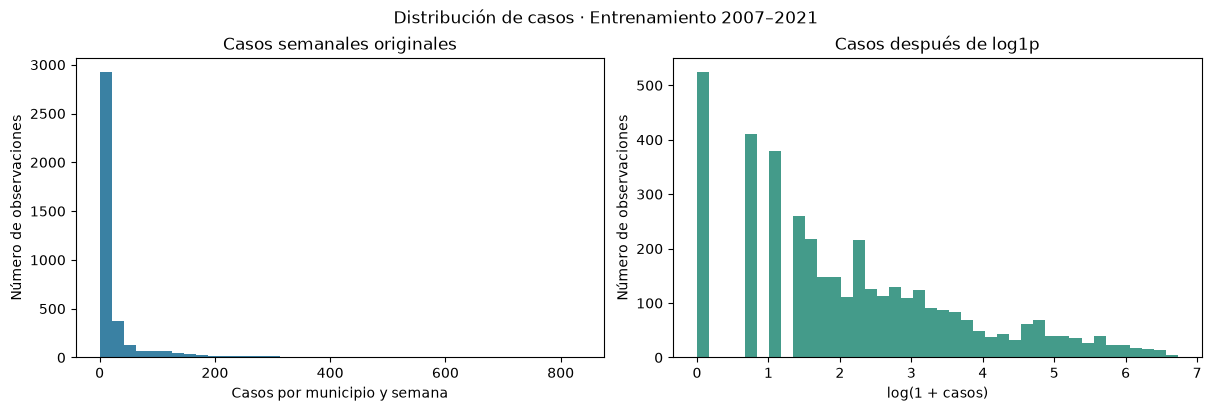

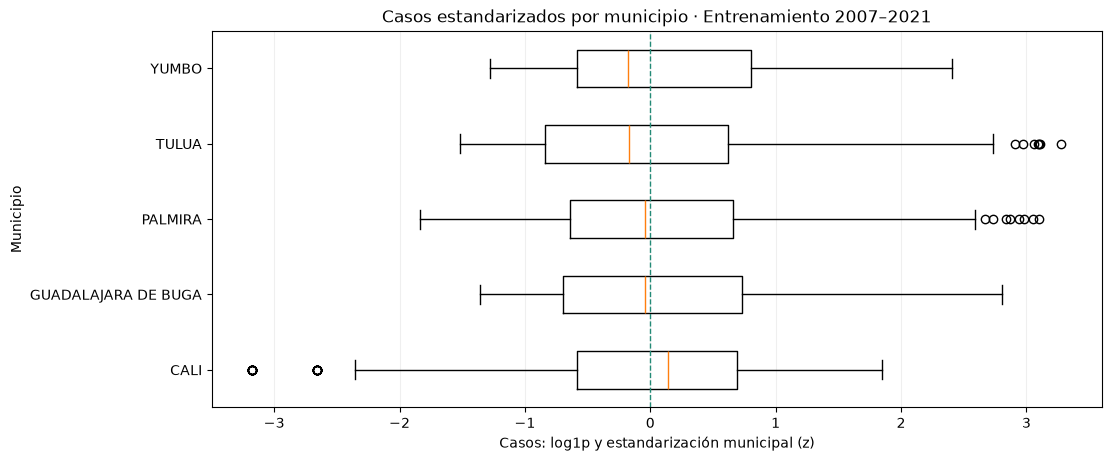

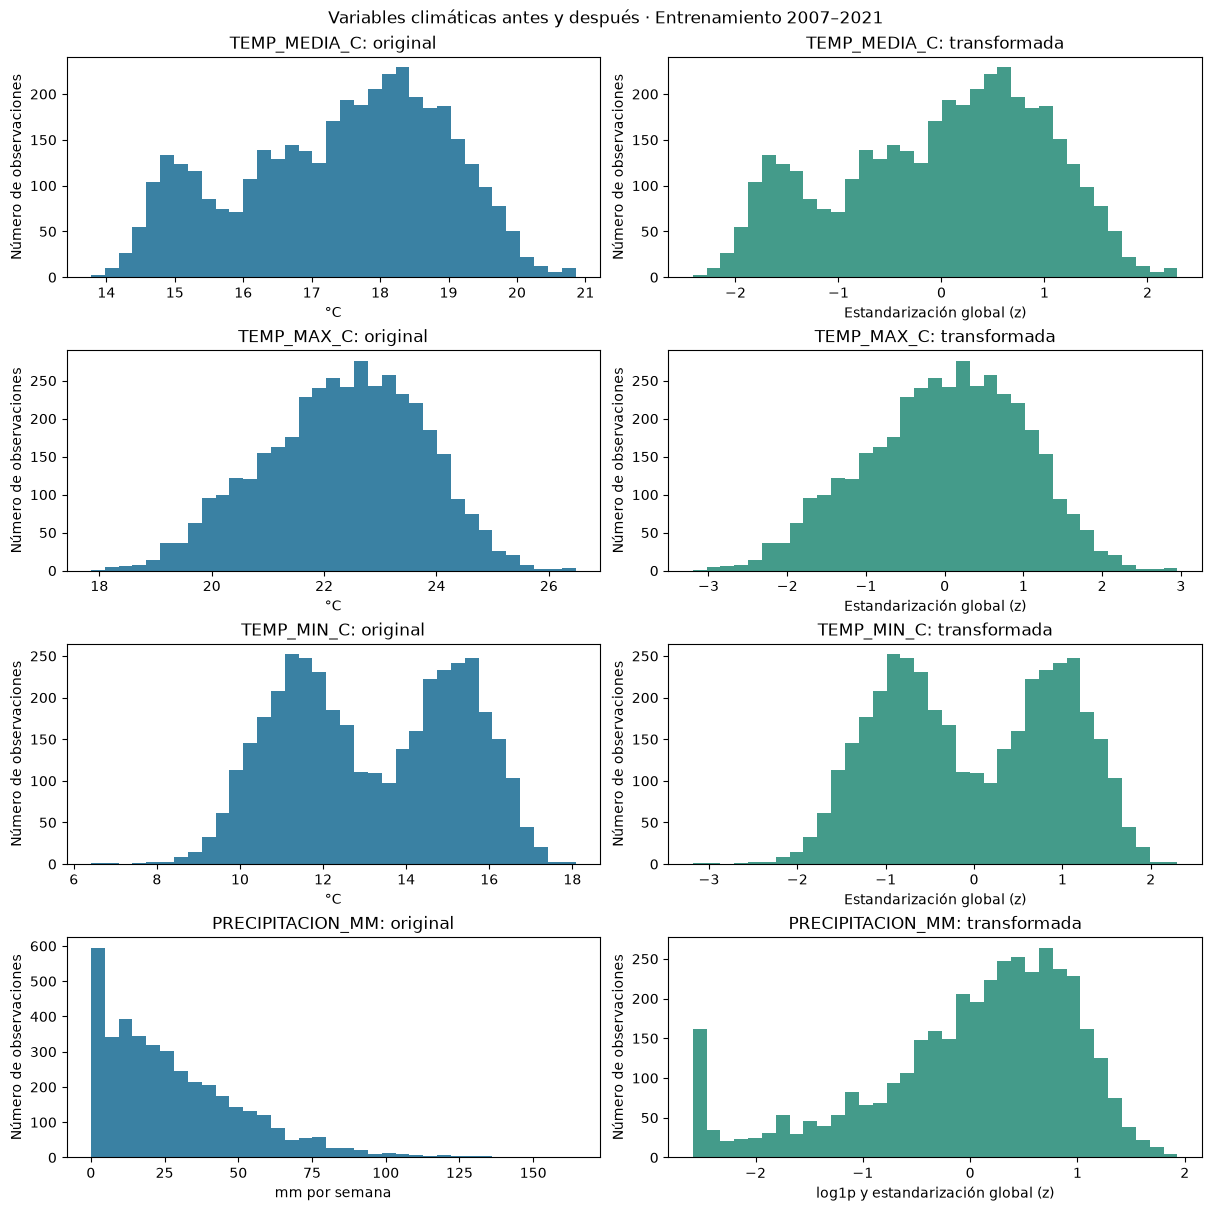

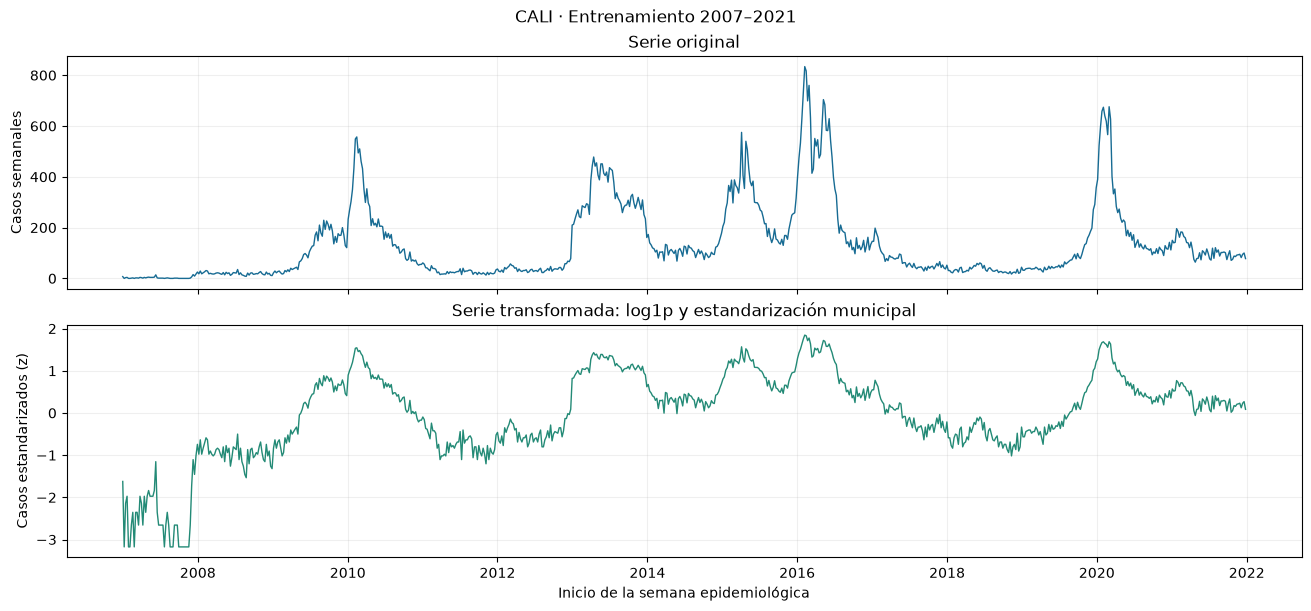

In [29]:
entrenamiento_graficas_lstm = df_lstm_entrenamiento
nombres_municipios_lstm = entrenamiento_graficas_lstm.groupby(ID_LSTM)['MUNICIPIO'].first().to_dict()
azul_lstm, verde_lstm = '#176B93', '#238A76'

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for eje, columna, titulo, etiqueta, color in [
    (ejes[0], 'CASOS', 'Casos semanales originales', 'Casos por municipio y semana', azul_lstm),
    (ejes[1], 'CASOS_log1p', 'Casos después de log1p', 'log(1 + casos)', verde_lstm),
]:
    eje.hist(entrenamiento_graficas_lstm[columna], bins=40, color=color, alpha=0.85)
    eje.set(title=titulo, xlabel=etiqueta, ylabel='Número de observaciones')
fig.suptitle('Distribución de casos · Entrenamiento 2007–2021')
plt.show()

fig, eje = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
eje.boxplot(
    [entrenamiento_graficas_lstm.loc[entrenamiento_graficas_lstm[ID_LSTM].eq(m), 'CASOS_std'] for m in orden_municipios_lstm],
    tick_labels=[nombres_municipios_lstm[m] for m in orden_municipios_lstm],
    orientation='horizontal',
)
eje.axvline(0, color=verde_lstm, linewidth=1, linestyle='--')
eje.set(title='Casos estandarizados por municipio · Entrenamiento 2007–2021', xlabel='Casos: log1p y estandarización municipal (z)', ylabel='Municipio')
eje.grid(axis='x', alpha=0.2)
plt.show()

fig, ejes = plt.subplots(len(CLIMA_LSTM), 2, figsize=(12, 12), constrained_layout=True)
for fila, columna in enumerate(CLIMA_LSTM):
    es_lluvia = columna == PRECIPITACION_LSTM
    unidad = 'mm por semana' if es_lluvia else '°C'
    etiqueta_transformada = 'log1p y estandarización global (z)' if es_lluvia else 'Estandarización global (z)'
    ejes[fila, 0].hist(entrenamiento_graficas_lstm[columna], bins=35, color=azul_lstm, alpha=0.85)
    ejes[fila, 0].set(title=f'{columna}: original', xlabel=unidad, ylabel='Número de observaciones')
    ejes[fila, 1].hist(entrenamiento_graficas_lstm[f'{columna}_std'], bins=35, color=verde_lstm, alpha=0.85)
    ejes[fila, 1].set(title=f'{columna}: transformada', xlabel=etiqueta_transformada, ylabel='Número de observaciones')
fig.suptitle('Variables climáticas antes y después · Entrenamiento 2007–2021')
plt.show()

municipio_grafica_lstm = orden_municipios_lstm[0]  # Cali (76001), presente en los datos.
serie_grafica_lstm = entrenamiento_graficas_lstm.loc[entrenamiento_graficas_lstm[ID_LSTM].eq(municipio_grafica_lstm)]
fig, ejes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, constrained_layout=True)
ejes[0].plot(serie_grafica_lstm['FECHA_INICIO'], serie_grafica_lstm['CASOS'], color=azul_lstm, linewidth=1)
ejes[0].set(title='Serie original', ylabel='Casos semanales')
ejes[1].plot(serie_grafica_lstm['FECHA_INICIO'], serie_grafica_lstm['CASOS_std'], color=verde_lstm, linewidth=1)
ejes[1].set(title='Serie transformada: log1p y estandarización municipal', xlabel='Inicio de la semana epidemiológica', ylabel='Casos estandarizados (z)')
for eje in ejes:
    eje.grid(alpha=0.2)
fig.suptitle(f'{nombres_municipios_lstm[municipio_grafica_lstm]} · Entrenamiento 2007–2021')
plt.show()


### 12.4. Datos y funciones disponibles para el modelado

Al terminar esta sección quedan disponibles los siguientes objetos. Sus nombres conservan el sufijo `lstm`, aunque sus transformaciones también se reutilizan en los demás modelos.

| Objeto | Contenido |
| --- | --- |
| `df_lstm_entrenamiento`, `df_lstm_validacion`, `df_lstm_test` | Tablas transformadas, separadas por periodo, con una fila por municipio y semana. |
| `conjuntos_transformados_lstm` | Las mismas tablas, agrupadas con las claves `training`, `validation` y `test`. |
| `columnas_entrada_lstm` | Siete entradas: casos, tres temperaturas, precipitación, seno y coseno de la semana, con las transformaciones descritas. |
| `columna_objetivo_lstm` | `CASOS_std`, la variable que aprenderán a pronosticar los modelos. |
| `escaladores_casos_lstm` | Los cinco escaladores de casos, identificados por `COD_DANE`. |
| `escaladores_clima_lstm` | Los escaladores de temperatura y precipitación. |
| `invertir_casos_lstm` | Función para recuperar el número de casos con el escalador municipal correspondiente. |
| `orden_municipios_lstm`, `semanas_por_ano_lstm` | Orden de los municipios y calendario de 52 o 53 semanas. |
| `auditoria_ajuste_lstm`, `verificacion_integridad_lstm`, `faltantes_lstm` | Comprobaciones del ajuste y de los datos transformados. |

Las columnas originales y los identificadores se conservan, pero las entradas numéricas del modelo son solo las indicadas en `columnas_entrada_lstm`. La representación del municipio para los modelos globales se incorpora en la preparación de secuencias del punto 13.


Las secuencias se forman por municipio: una ventana nunca debe continuar con las semanas de otra ciudad. Para pronosticar t+4 utilizamos información hasta t, sin añadir los casos ni el clima observado de las semanas futuras.

Los objetos de esta sección se crean en memoria. Después de reiniciar el kernel, esta parte puede recuperar los CSV semanales y ajustar de nuevo los escaladores con entrenamiento, sin releer los archivos anuales. El modelado del punto 13 recupera las transformaciones guardadas con los experimentos que se están comparando.


## 13. Preparar las secuencias y definir la comparación

Cada ejemplo utiliza la historia de un municipio para pronosticar **los casos de la semana t+4**. Comparamos ventanas de 12, 16 y 20 semanas sobre las mismas fechas: **3.800 ejemplos de entrenamiento** y **505 de validación**, equivalentes a 760 y 101 por municipio. Los objetivos de validación van del 23 de enero de 2022 al 24 de diciembre de 2023.

Las siete entradas temporales son los casos, las tres temperaturas, la precipitación y el seno y coseno de la semana. A los modelos globales añadimos cinco indicadores municipales mediante **one-hot encoding**: uno vale 1 para el municipio del ejemplo y los demás valen 0. Así el modelo puede distinguir las ciudades sin interpretar su código como una cantidad.

Recuperamos los escaladores y las secuencias guardados con los experimentos. El código comprueba que coincidan con las tablas semanales, que las entradas terminen en t y que el objetivo corresponda a t+4.

Desde este punto hasta el 19 usamos solo entrenamiento y validación. Por defecto se cargan los modelos ya entrenados para revisar sus resultados. Las funciones están en `exploracion_temporal.py`; en el punto 17 se puede activar una nueva ejecución si se decide repetir la exploración.


In [30]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display,Markdown,Image
from exploracion_temporal import (
    cargar_desarrollo, recuperar_resultados, RECETAS, HISTORIAS,
    iniciar_experimento, ejecutar_ajustes, comparar_desarrollo, graficar_desarrollo,
    guardar_desarrollo, resumir_validacion, conclusiones_desarrollo,
    evaluar_al_cierre, graficar_al_cierre,
)

RUTA_DESARROLLO = Path('ResultadosModelos\\exploracion_temporal_validacion\\ejecucion_291cbf82')
datos_desarrollo, preprocesamiento_desarrollo = cargar_desarrollo()
(predicciones_desarrollo, metricas_desarrollo, metricas_municipales_desarrollo,
 ranking_validacion, seleccion_validacion, catalogo_entrenado) = recuperar_resultados(RUTA_DESARROLLO)
display(pd.DataFrame([{'HISTORIA':v,'CONJUNTO':c,'FORMA_X':str(d['X'].shape),
    'FORMA_Y':str(d['y'].shape),'MUNICIPIOS':d['meta']['COD_DANE'].nunique()}
    for v,g in datos_desarrollo.items() for c,d in g.items()]))
print('Solo entrenamiento y validación. Evaluación desactivada.')


,HISTORIA,CONJUNTO,FORMA_X,FORMA_Y,MUNICIPIOS
0,12,training,"(3800, 12, 7)","(3800, 1)",5
1,12,validation,"(505, 12, 7)","(505, 1)",5
2,16,training,"(3800, 16, 7)","(3800, 1)",5
3,16,validation,"(505, 16, 7)","(505, 1)",5
4,20,training,"(3800, 20, 7)","(3800, 1)",5
5,20,validation,"(505, 20, 7)","(505, 1)",5


Solo entrenamiento y validación. Evaluación desactivada.


## 14. Revisar la comparación inicial de historias

La tabla recupera el primer experimento con 12, 16 y 20 semanas. En las LSTM globales se mantuvo una capa de 32 unidades al cambiar la historia; los demás modelos conservaron sus configuraciones. Sirve como punto de partida para la comparación ampliada del punto 18.

Durante la validación avanzamos semana a semana, incorporando la información disponible hasta cada t y manteniendo los pesos fijos. Por tanto, no estamos pronosticando los dos años completos desde una sola fecha. El objetivo t+4 es el conteo de una semana futura, no la suma de casos del mes.


In [31]:
historias_iniciales = pd.read_csv(
    'ResultadosModelos/historia_12_16_20_t4/ejecucion_ba352a18/metricas_tres_ventanas.csv',encoding='utf-8-sig')
display(historias_iniciales[['LOOKBACK','MODELO','N_PRONOSTICOS','MAE','RMSE']].style.format({'MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))


LOOKBACK,MODELO,N_PRONOSTICOS,MAE,RMSE
12,LSTM global,505,12.292,29.636
12,LSTM local,505,18.680,47.174
12,Random Forest,505,15.731,39.453
12,Regresión lineal,505,14.881,37.025
16,LSTM global,505,11.627,27.738
16,LSTM local,505,15.782,38.966
16,Random Forest,505,15.201,38.171
16,Regresión lineal,505,14.885,36.312
20,LSTM global,505,12.154,28.005
20,LSTM local,505,15.178,37.697


## 15. Comparar regresión lineal, Random Forest y XGBoost

Estos modelos necesitan una tabla bidimensional. Por eso colocamos los valores de cada secuencia en una sola fila y añadimos los cinco indicadores municipales. El resultado tiene **89, 117 o 145 predictores** para historias de 12, 16 o 20 semanas. Dentro de cada historia, los tres modelos reciben las mismas entradas y objetivos.

La regresión lineal conserva su configuración inicial. Random Forest utiliza 300 árboles, profundidad máxima de 12, al menos tres observaciones por hoja y semilla 42.

XGBoost usa hasta 800 rondas, profundidad de 3, tasa de aprendizaje de 0,03, muestreo de filas y columnas de 0,8, regularización L2 de 1 y semilla 42. El número de rondas se decide con el RMSE de validación en la escala transformada: si deja de mejorar durante 50 rondas, el ajuste se detiene. Se completaron los experimentos de 12 y 20 semanas con esa misma configuración.

La tabla distingue los errores de entrenamiento y validación, ya expresados en casos. El número de árboles y el número de parámetros de una red describen estructuras distintas; no son medidas directamente equivalentes.


MODELO,HISTORIA,CONJUNTO,N,MAE,RMSE
Regresión lineal · 12s,12,training,3800,10.603,31.420
Regresión lineal · 12s,12,validation,505,14.881,37.025
Random Forest · 12s,12,training,3800,5.310,15.469
Random Forest · 12s,12,validation,505,15.731,39.453
XGBoost · 12s,12,training,3800,8.417,24.996
XGBoost · 12s,12,validation,505,15.681,38.750
Regresión lineal · 16s,16,training,3800,10.454,30.958
Regresión lineal · 16s,16,validation,505,14.885,36.312
Random Forest · 16s,16,training,3800,5.172,14.950
Random Forest · 16s,16,validation,505,15.201,38.171


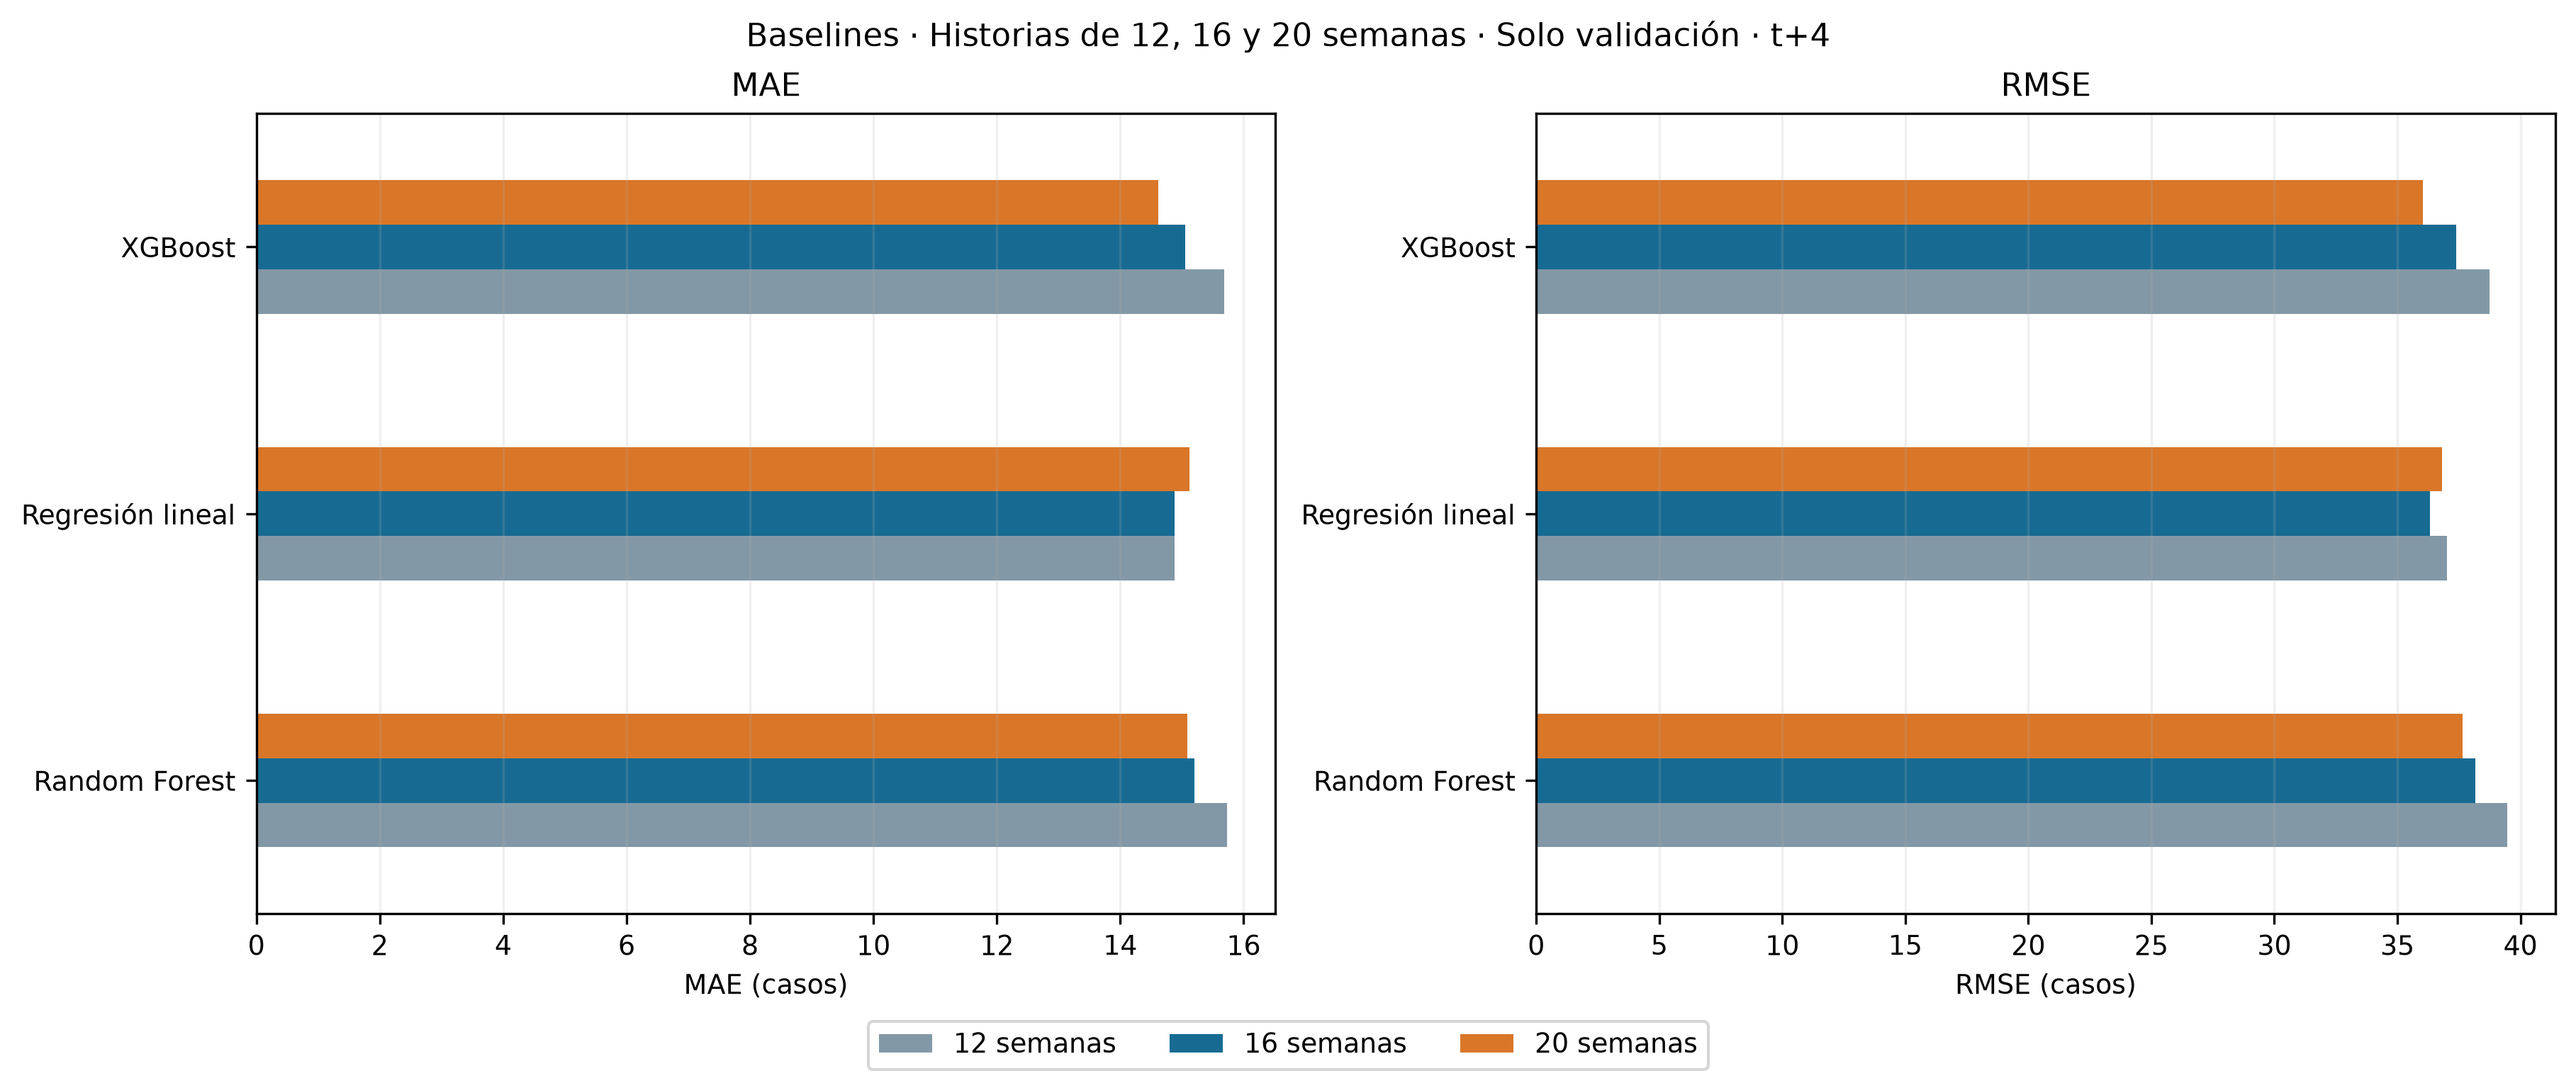

In [32]:
familias_baseline = ['Regresión lineal','Random Forest','XGBoost']
comparacion_baselines = metricas_desarrollo.loc[metricas_desarrollo['FAMILIA'].isin(familias_baseline)]
display(comparacion_baselines[['MODELO','HISTORIA','CONJUNTO','N','MAE','RMSE']].style.format({'MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))
display(Image(filename=str(RUTA_DESARROLLO/'figuras/10_baselines_historias_validacion.png')))


## 16. Recuperar las redes de referencia

Conservamos las LSTM globales originales de las tres historias, la GRU de 16 semanas, la LSTM de 16 semanas con Dropout de 0,20 y las variantes de 64 unidades y dos capas de 32. También incluimos los modelos locales: cinco redes por historia, una para cada municipio.

Las redes globales procesan cada historia municipal y añaden su representación one-hot después de las capas recurrentes, antes de la capa densa intermedia o de la salida. Las locales reciben únicamente las secuencias de su municipio.

La tabla muestra sus errores de validación. Para los modelos locales, la cantidad de parámetros es la suma de las cinco redes.


In [33]:
ids_reutilizados = [r['ID'] for r in catalogo_entrenado if r['REUTILIZADO']]
referencias_recurrentes = ranking_validacion.loc[
    ranking_validacion['ID'].isin(ids_reutilizados)&ranking_validacion['FAMILIA'].isin(['LSTM','GRU','LSTM local'])]
display(referencias_recurrentes[['MODELO','HISTORIA','PARAMETROS_RED','MAE','RMSE']].style.format(
    {'PARAMETROS_RED':'{:.0f}','MAE':'{:.3f}','RMSE':'{:.3f}'},na_rep='No aplica').hide(axis='index'))


MODELO,HISTORIA,PARAMETROS_RED,MAE,RMSE
LSTM 32 · Dense16 · D0 · 16s,16,5745,11.627,27.738
LSTM 32 · Dense16 · D0 · 20s,20,5745,12.154,28.005
"LSTM 32 · Dense16 · D0,20 · 16s",16,5745,12.155,28.644
GRU 32 · Dense16 · D0 · 16s,16,4561,12.286,29.455
LSTM 32 · Dense16 · D0 · 12s,12,5745,12.292,29.636
LSTM 64 · Dense16 · D0 · 16s,16,19569,13.984,34.789
LSTM 32→32 · Dense16 · D0 · 16s,16,14065,14.198,35.333
LSTM local (5 redes) · 20s,20,28325,15.178,37.697
LSTM local (5 redes) · 16s,16,28325,15.782,38.966
LSTM local (5 redes) · 12s,12,28325,18.680,47.174


## 17. Probar otras estructuras de LSTM y GRU

Probamos seis estructuras en cada familia y con cada historia: **36 combinaciones**. Partimos de una capa recurrente de 32 unidades y una capa densa intermedia de 16. A partir de ella probamos quitar la capa densa, añadir Dropout de 0,20 o 0,50 y apilar dos o tres capas recurrentes.

Las redes profundas usan 32→16 o 32→16→8 unidades y Dropout de 0,20 después de cada capa recurrente. Las capas anteriores a la última entregan la secuencia completa a la siguiente. Después se añade la identidad municipal y todas las redes terminan en una neurona lineal para t+4.

Aquí Dropout se aplica a la salida de las capas durante el entrenamiento; no utilizamos `recurrent_dropout`. Durante la predicción está desactivado.

Mantenemos semilla 42, Adam con tasa de aprendizaje de 0,001, lotes de 32, hasta 100 épocas y `shuffle=False`. EarlyStopping detiene el ajuste tras 10 épocas sin mejorar el MSE de validación y recupera los mejores pesos. ReduceLROnPlateau reduce la tasa de aprendizaje tras 5 épocas sin mejora. Cada entrenamiento nuevo empieza con sus propios pesos, optimizador y callbacks.

Cinco de las 36 redes ya estaban entrenadas y se reutilizaron; las otras 31 se entrenaron para esta comparación. Las estructuras se definieron antes de ejecutar los ajustes. Es una exploración limitada a estas opciones y una semilla, sin búsqueda exhaustiva.


In [34]:
tabla_recetas = pd.DataFrame([{'RECETA':r,'UNIDADES_RECURRENTES':' → '.join(map(str,c['unidades'])),
    'DENSE_INTERMEDIA':c['dense'] if c['dense'] else 'Sin capa intermedia','DROPOUT':c['dropout']}
    for r,c in RECETAS.items()])
display(tabla_recetas)
print('Misma lista para LSTM/GRU e historias de 12, 16 y 20 semanas.')


,RECETA,UNIDADES_RECURRENTES,DENSE_INTERMEDIA,DROPOUT
0,referencia,32,16,0.0
1,sin_dense,32,Sin capa intermedia,0.0
2,drop20,32,16,0.2
3,drop50,32,16,0.5
4,dos_capas,32 → 16,16,0.2
5,tres_capas,32 → 16 → 8,16,0.2


Misma lista para LSTM/GRU e historias de 12, 16 y 20 semanas.


In [35]:
# Los resultados mostrados ya fueron entrenados y verificados.
# Activa esta opción solo para crear otra ejecución con las recetas del módulo.
REENTRENAR_EXPLORACION = False
if REENTRENAR_EXPLORACION:
    RUTA_DESARROLLO, catalogo_inicial = iniciar_experimento()
    catalogo_entrenado = ejecutar_ajustes(datos_desarrollo,RUTA_DESARROLLO,catalogo_inicial)
    (predicciones_desarrollo,metricas_desarrollo,metricas_municipales_desarrollo,
     ranking_validacion,seleccion_validacion) = comparar_desarrollo(
        datos_desarrollo,preprocesamiento_desarrollo,catalogo_entrenado,RUTA_DESARROLLO)
    catalogo_entrenado = json.loads((RUTA_DESARROLLO/'catalogo_modelos.json').read_text(encoding='utf-8'))
    figuras_desarrollo = graficar_desarrollo(predicciones_desarrollo,metricas_desarrollo,
        metricas_municipales_desarrollo,ranking_validacion,catalogo_entrenado,RUTA_DESARROLLO,mostrar=False)
    guardar_desarrollo(RUTA_DESARROLLO,predicciones_desarrollo,metricas_desarrollo,
        metricas_municipales_desarrollo,ranking_validacion,catalogo_entrenado,figuras_desarrollo)
else:
    print('Se recuperan 50 configuraciones guardadas. No se ejecutó ningún entrenamiento adicional.')

resumen_ajustes = pd.DataFrame(catalogo_entrenado)
columnas_resumen = ['NOMBRE','REUTILIZADO','PARAMETROS_RED','MEJOR_PASO','PASOS_EJECUTADOS']
display(resumen_ajustes.reindex(columns=columnas_resumen).style.format(
    {'PARAMETROS_RED':'{:.0f}','MEJOR_PASO':'{:.0f}','PASOS_EJECUTADOS':'{:.0f}'},na_rep='No aplica').hide(axis='index'))


Se recuperan 50 configuraciones guardadas. No se ejecutó ningún entrenamiento adicional.


NOMBRE,REUTILIZADO,PARAMETROS_RED,MEJOR_PASO,PASOS_EJECUTADOS
LSTM 32 · Dense16 · D0 · 12s,True,5745,27,37
LSTM 32 · sin Dense intermedia · 12s,False,5158,24,34
"LSTM 32 · Dense16 · D0,20 · 12s",False,5745,18,28
"LSTM 32 · Dense16 · D0,50 · 12s",False,5745,43,53
"LSTM 32→16 · Dense16 · D0,20 · 12s",False,8625,29,39
"LSTM 32→16→8 · Dense16 · D0,20 · 12s",False,9297,43,53
GRU 32 · Dense16 · D0 · 12s,False,4561,82,92
GRU 32 · sin Dense intermedia · 12s,False,3974,73,83
"GRU 32 · Dense16 · D0,20 · 12s",False,4561,26,36
"GRU 32 · Dense16 · D0,50 · 12s",False,4561,17,27


### 17.1. Revisar las curvas de aprendizaje

Las curvas muestran el error cuadrático medio (MSE) durante entrenamiento y validación, en la escala transformada de casos. La línea vertical marca la época con menor error de validación; esos son los pesos utilizados para predecir.

Estas curvas ayudan a revisar el ajuste, pero el orden de los modelos puede cambiar al medir MAE y RMSE en casos originales. Además, con Dropout la pérdida de entrenamiento se calcula mientras esa regularización está activa y la de validación, con Dropout desactivado.

`HISTORIA_PARA_CURVAS` permite elegir **12, 16 o 20 semanas**. Cambiar ese valor solo cambia las figuras mostradas; no vuelve a entrenar. Las seis figuras de aprendizaje están guardadas en la carpeta de resultados.


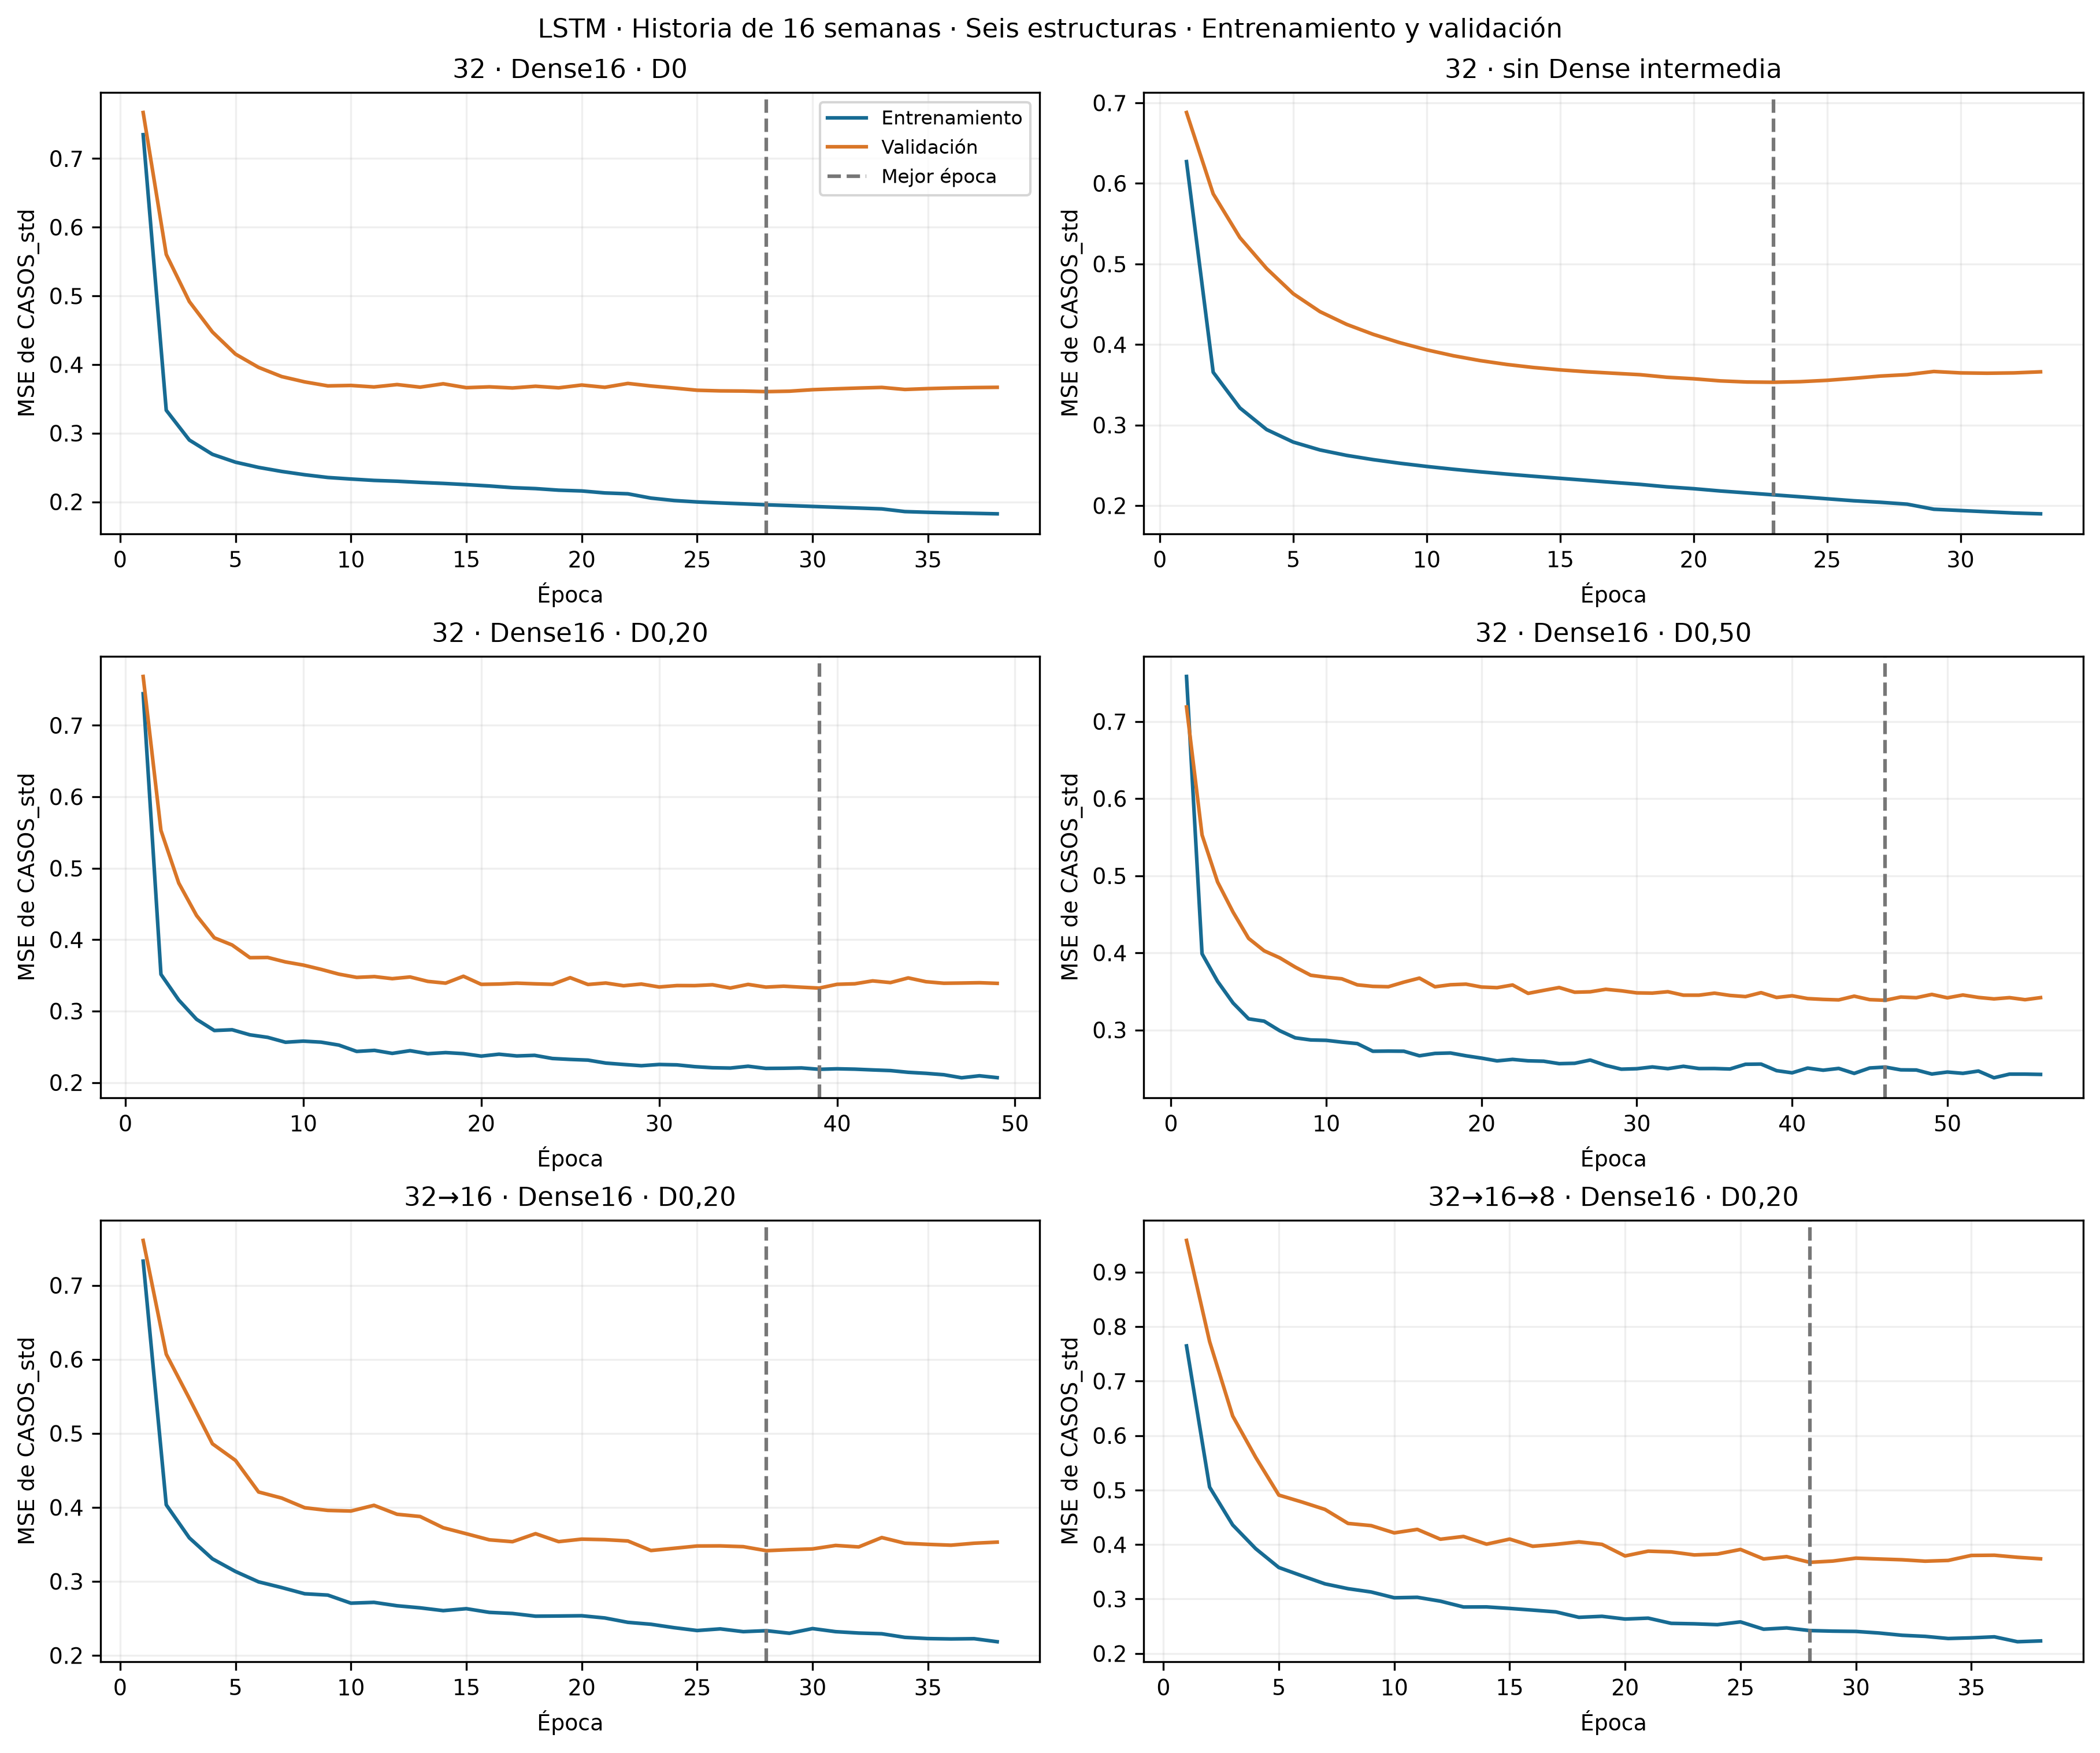

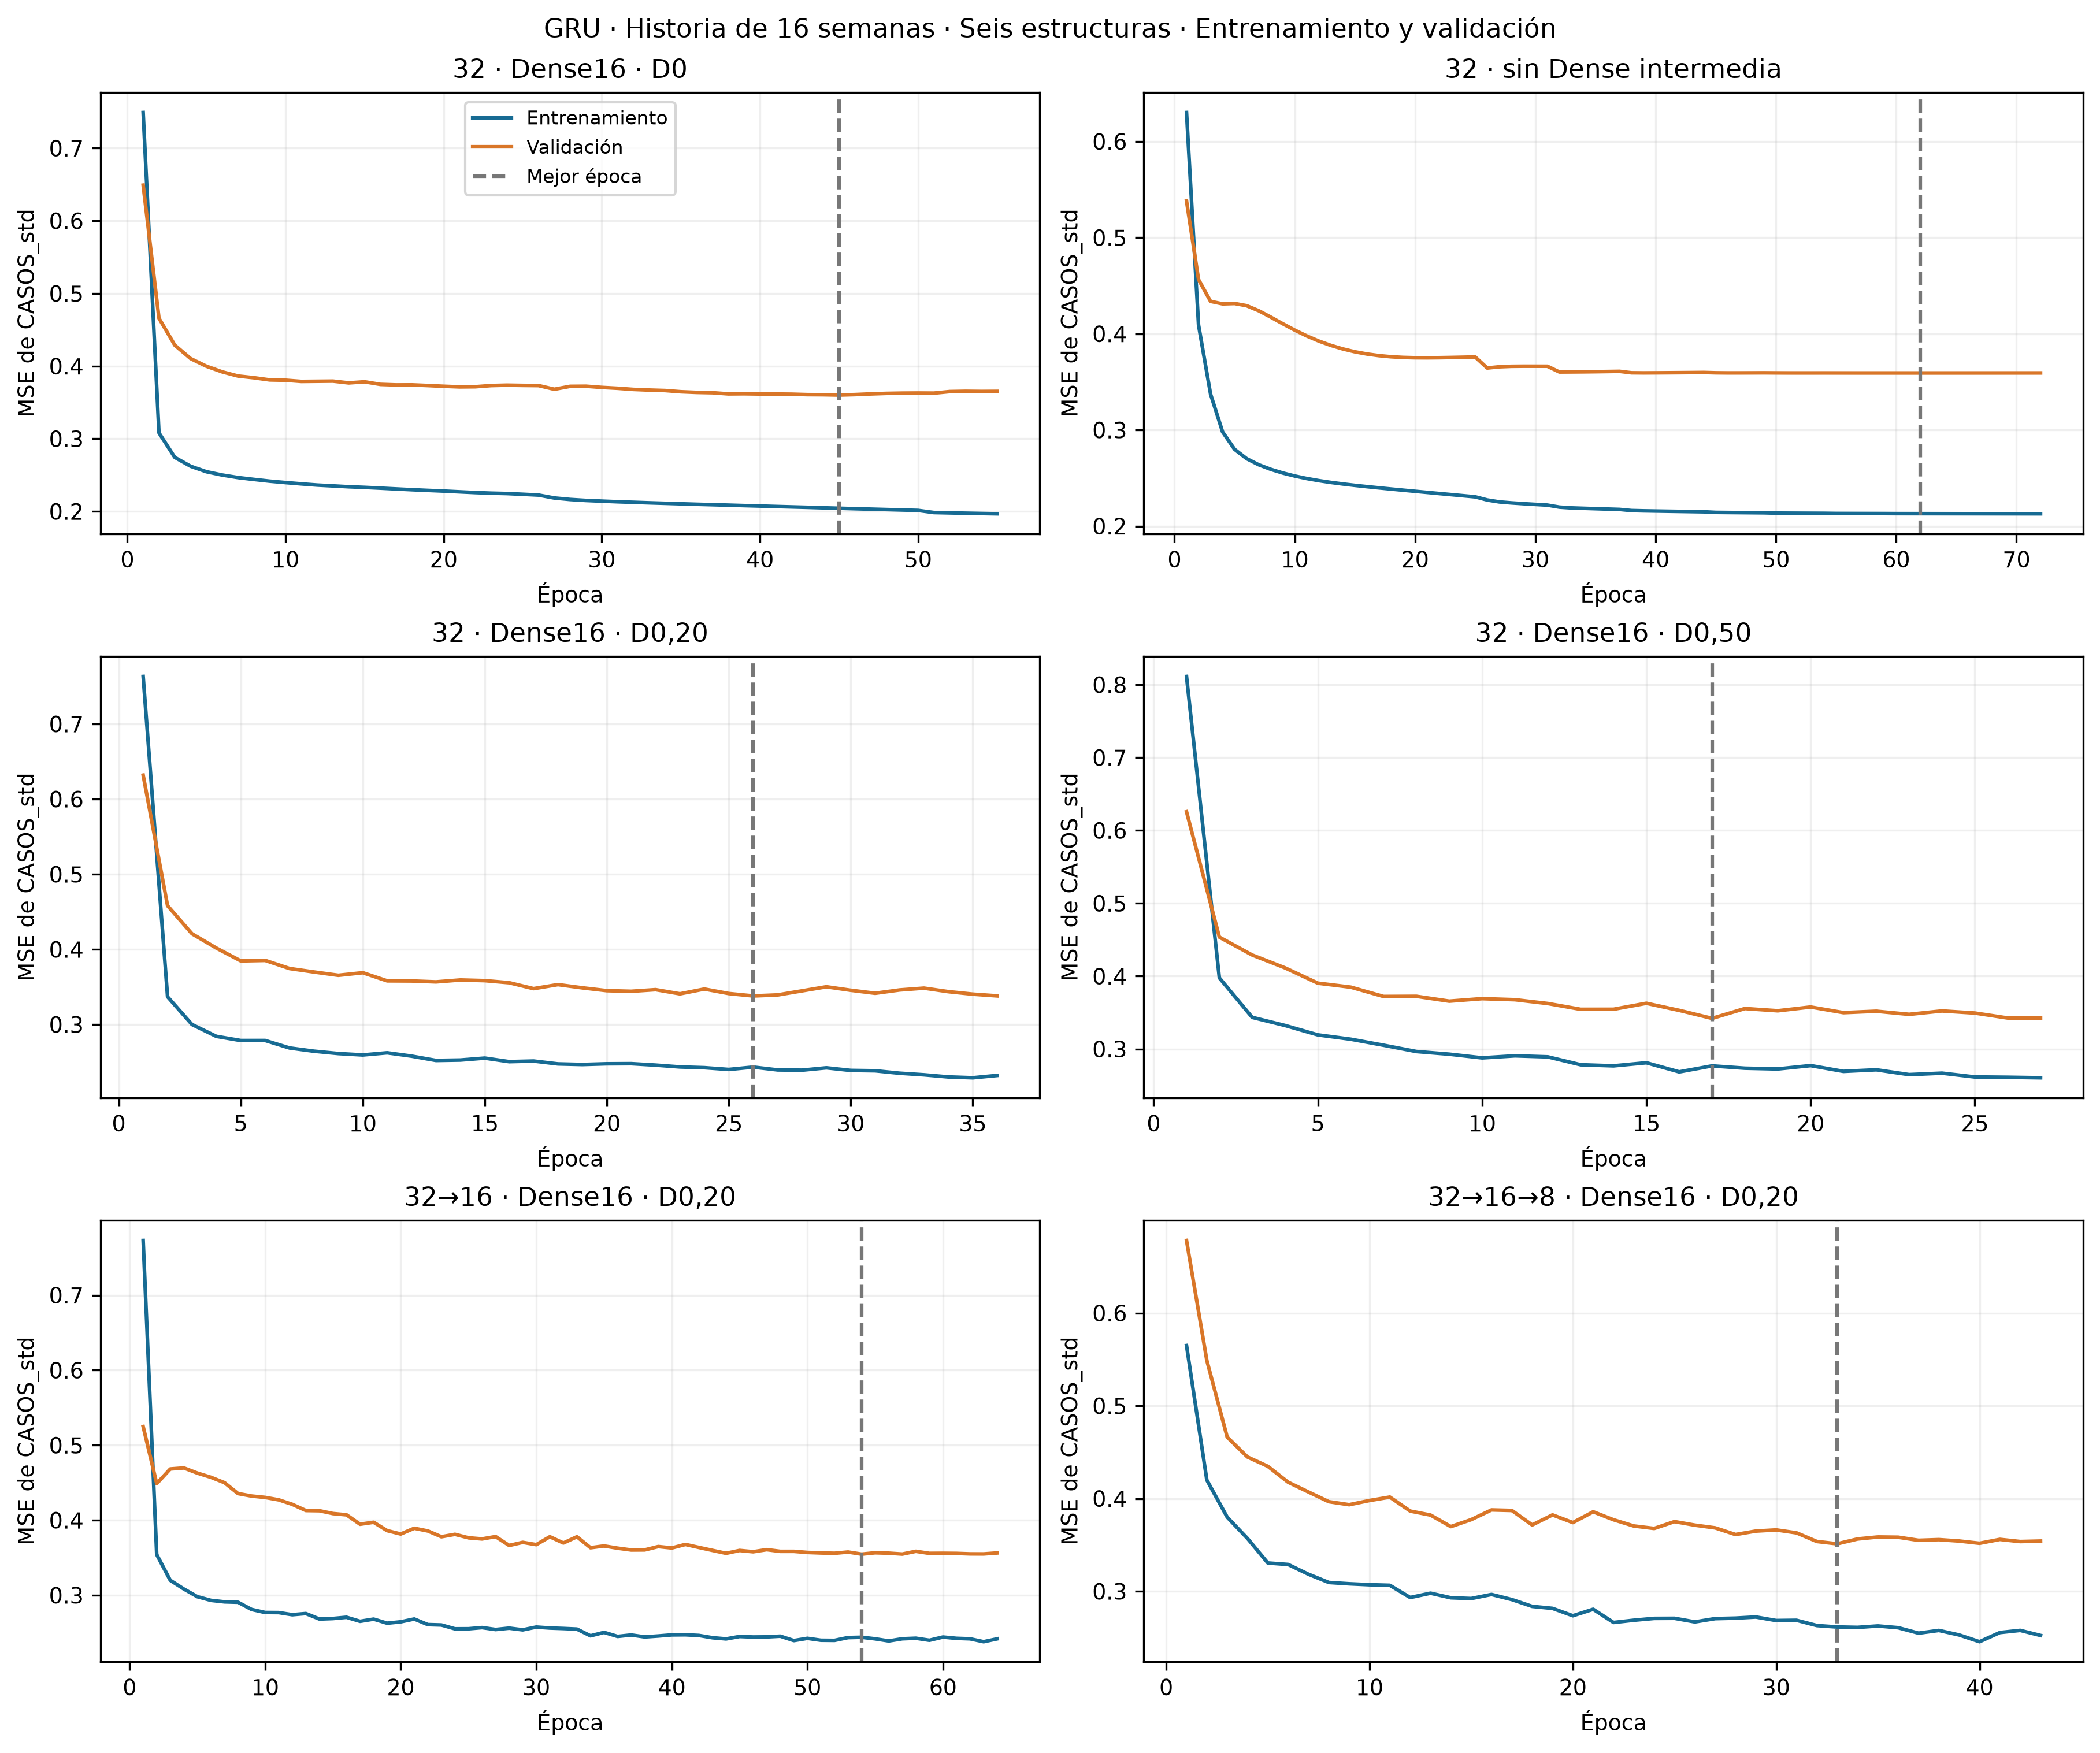

In [36]:
HISTORIA_PARA_CURVAS = 16
assert HISTORIA_PARA_CURVAS in HISTORIAS
for familia in ['lstm','gru']:
    display(Image(filename=str(RUTA_DESARROLLO/f'figuras/curvas_{familia}_{HISTORIA_PARA_CURVAS}.png')))


## 18. Comparar todos los modelos en validación

Ordenamos las **50 configuraciones** por MAE de validación, usando los valores sin redondear. El **MAE** indica cuánto se alejan las predicciones de los casos reales, en promedio. El **RMSE** da más peso a los errores grandes. Ambos se calculan después de recuperar la escala original con el escalador de cada municipio.

También revisamos el sesgo medio, la proporción de subestimaciones y los pronósticos negativos. Cada municipio aporta 101 objetivos, de modo que el MAE general coincide con el promedio de los cinco MAE municipales. Para RMSE, el promedio municipal se informa por separado porque no equivale al RMSE general.

Las figuras muestran la comparación de estructuras e historias, las quince configuraciones con menor MAE y las series de validación. En las series usamos un modelo por familia, elegido por su MAE general, y mantenemos ese mismo modelo para los cinco municipios.


MODELO,HISTORIA,N,MAE,RMSE,RMSE_PROMEDIO_MUNICIPAL,PRONOSTICOS_NEGATIVOS
LSTM 32 · Dense16 · D0 · 16s,16,505,11.627,27.738,22.329,1
"LSTM 32 · Dense16 · D0,20 · 20s",20,505,11.669,26.314,20.936,0
GRU 32 · Dense16 · D0 · 20s,20,505,12.083,28.829,22.980,0
"GRU 32 · Dense16 · D0,20 · 20s",20,505,12.118,29.294,23.330,0
LSTM 32 · Dense16 · D0 · 20s,20,505,12.154,28.005,22.485,1
"LSTM 32 · Dense16 · D0,20 · 16s",16,505,12.155,28.644,22.494,0
GRU 32 · Dense16 · D0 · 16s,16,505,12.286,29.455,23.452,0
LSTM 32 · Dense16 · D0 · 12s,12,505,12.292,29.636,23.522,1
"GRU 32 · Dense16 · D0,50 · 20s",20,505,12.294,29.412,23.462,0
GRU 32 · sin Dense intermedia · 20s,20,505,12.351,29.715,23.853,0


FAMILIA,HISTORIA,CONFIGURACIONES,MEJOR_MAE,MIN_MAE,MEJOR_RMSE,MIN_RMSE
LSTM,16,8,LSTM 32 · Dense16 · D0 · 16s,11.627,LSTM 32 · Dense16 · D0 · 16s,27.738
LSTM,20,6,"LSTM 32 · Dense16 · D0,20 · 20s",11.669,"LSTM 32 · Dense16 · D0,20 · 20s",26.314
GRU,20,6,GRU 32 · Dense16 · D0 · 20s,12.083,GRU 32 · Dense16 · D0 · 20s,28.829
GRU,16,6,GRU 32 · Dense16 · D0 · 16s,12.286,GRU 32 · Dense16 · D0 · 16s,29.455
LSTM,12,6,LSTM 32 · Dense16 · D0 · 12s,12.292,LSTM 32 · Dense16 · D0 · 12s,29.636
GRU,12,6,"GRU 32 · Dense16 · D0,20 · 12s",12.498,"GRU 32 · Dense16 · D0,20 · 12s",30.181
XGBoost,20,1,XGBoost · 20s,14.619,XGBoost · 20s,36.031
Regresión lineal,12,1,Regresión lineal · 12s,14.881,Regresión lineal · 12s,37.025
Regresión lineal,16,1,Regresión lineal · 16s,14.885,Regresión lineal · 16s,36.312
XGBoost,16,1,XGBoost · 16s,15.053,XGBoost · 16s,37.402


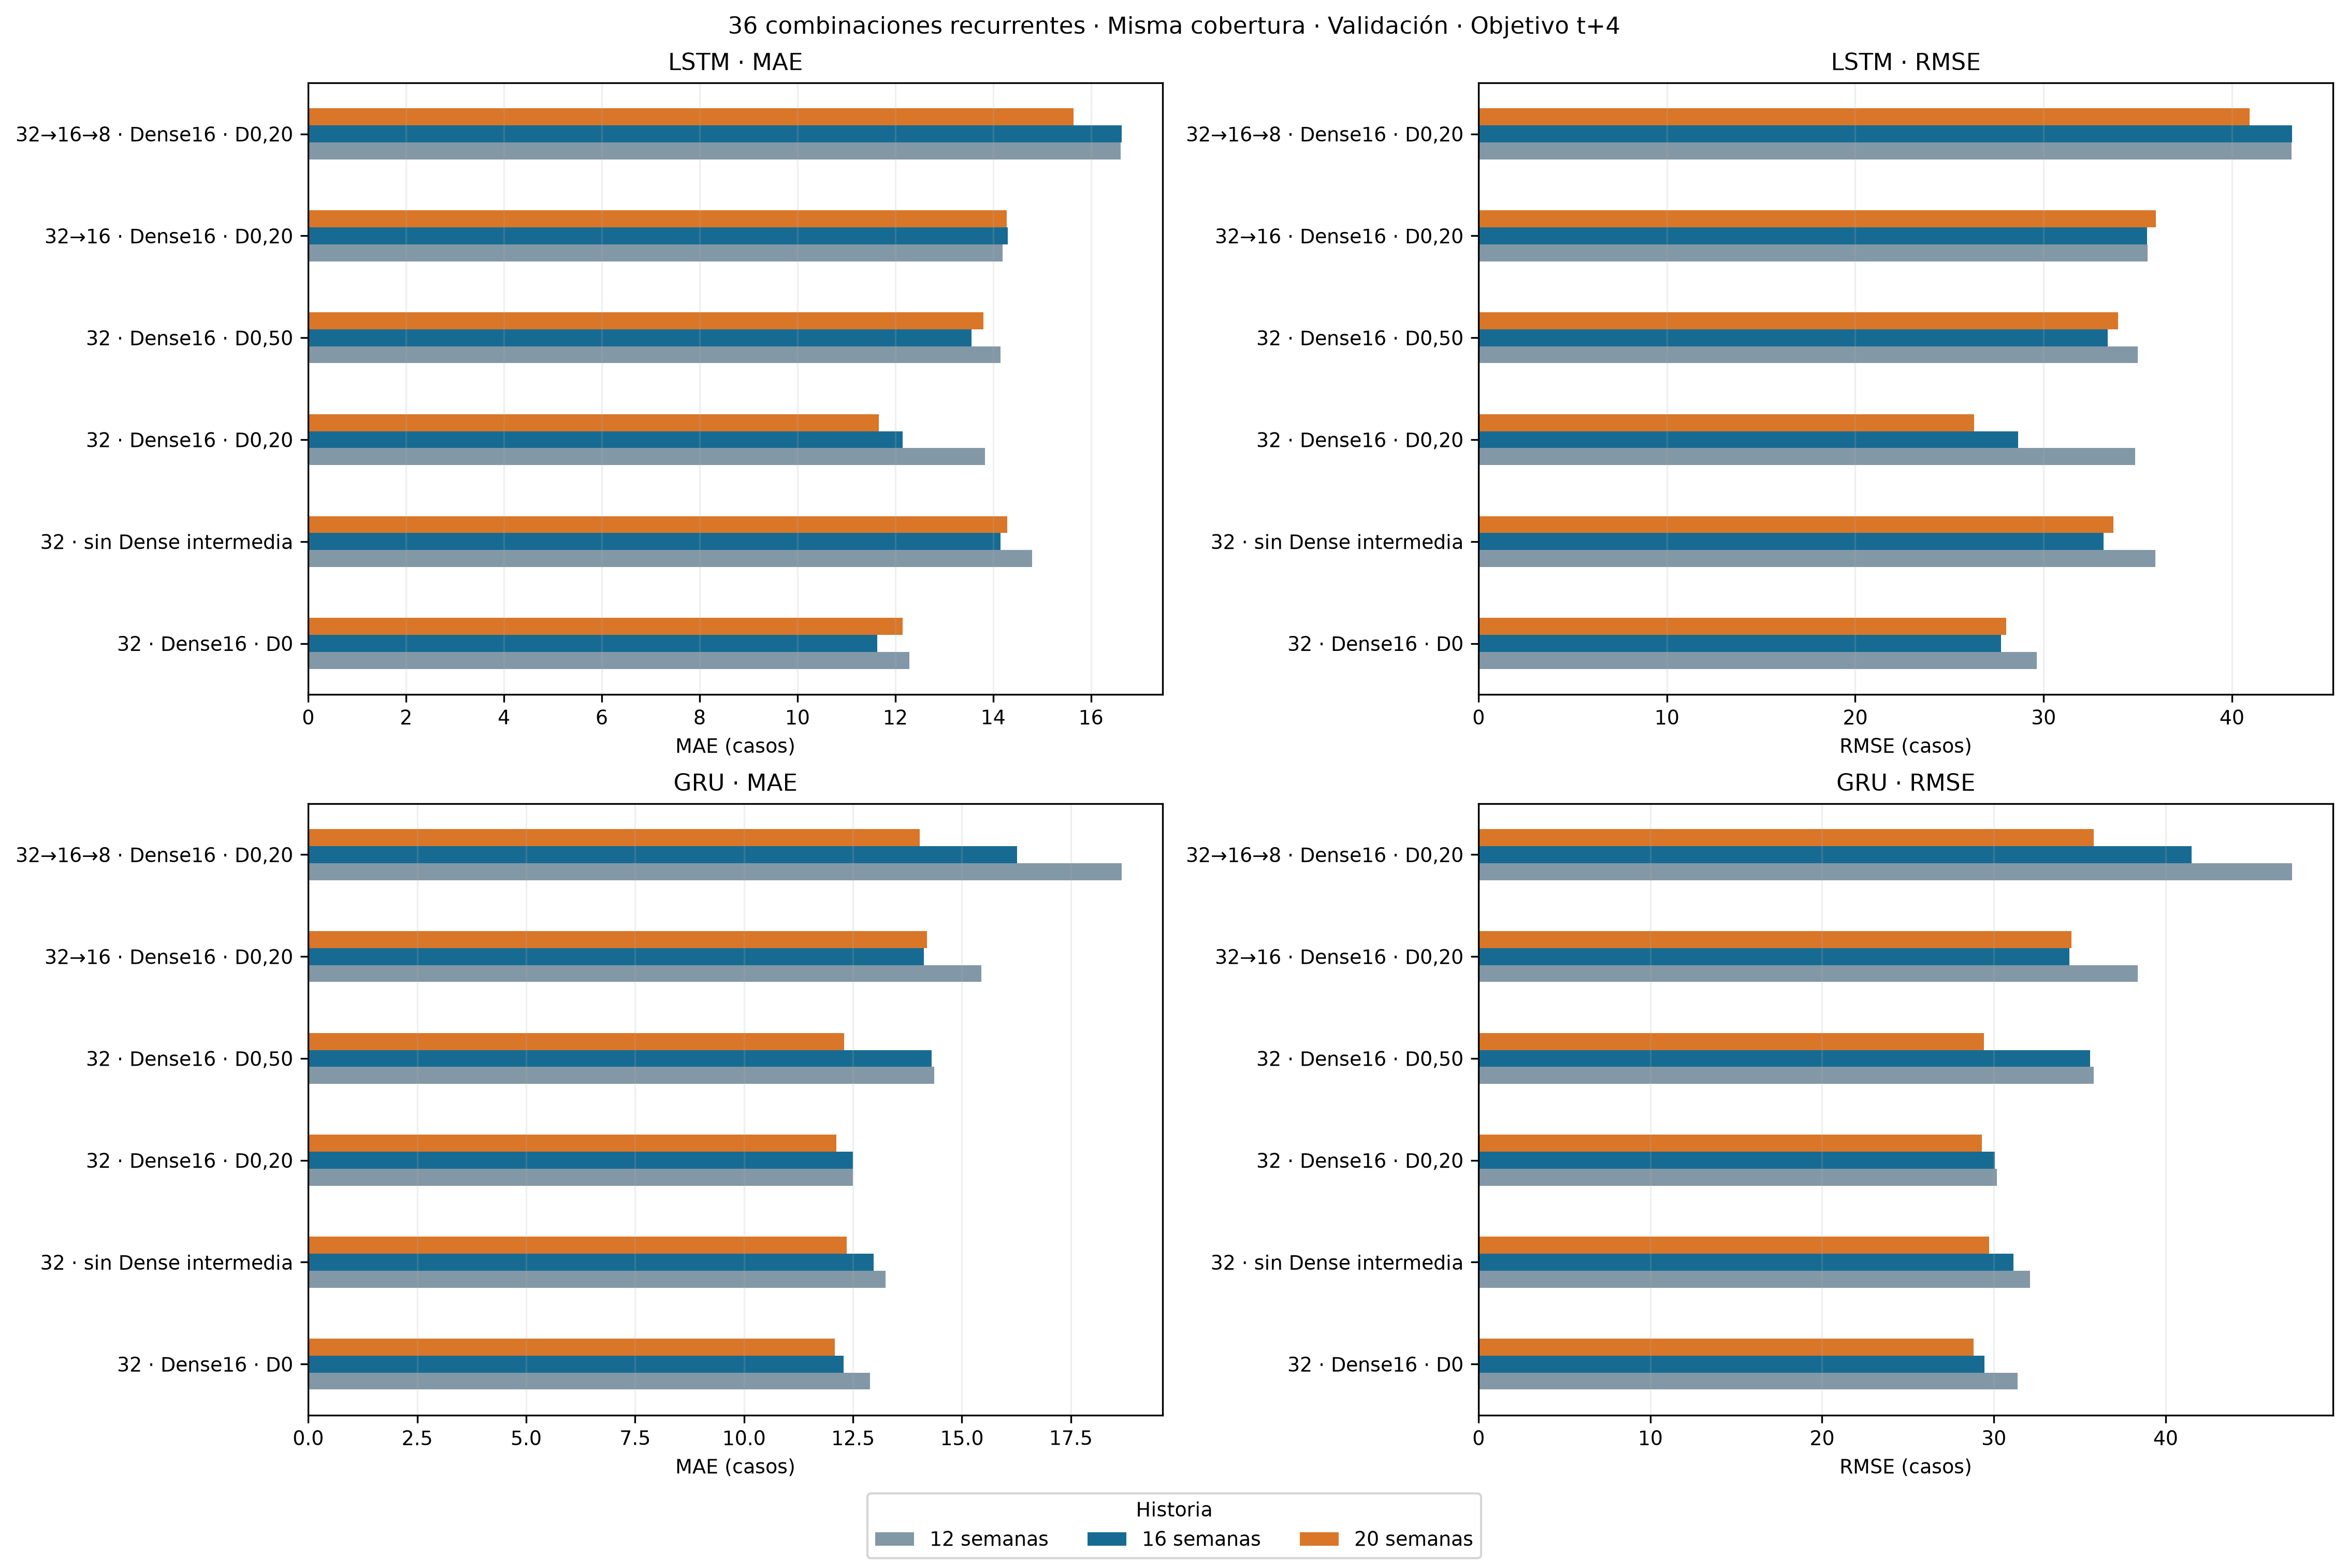

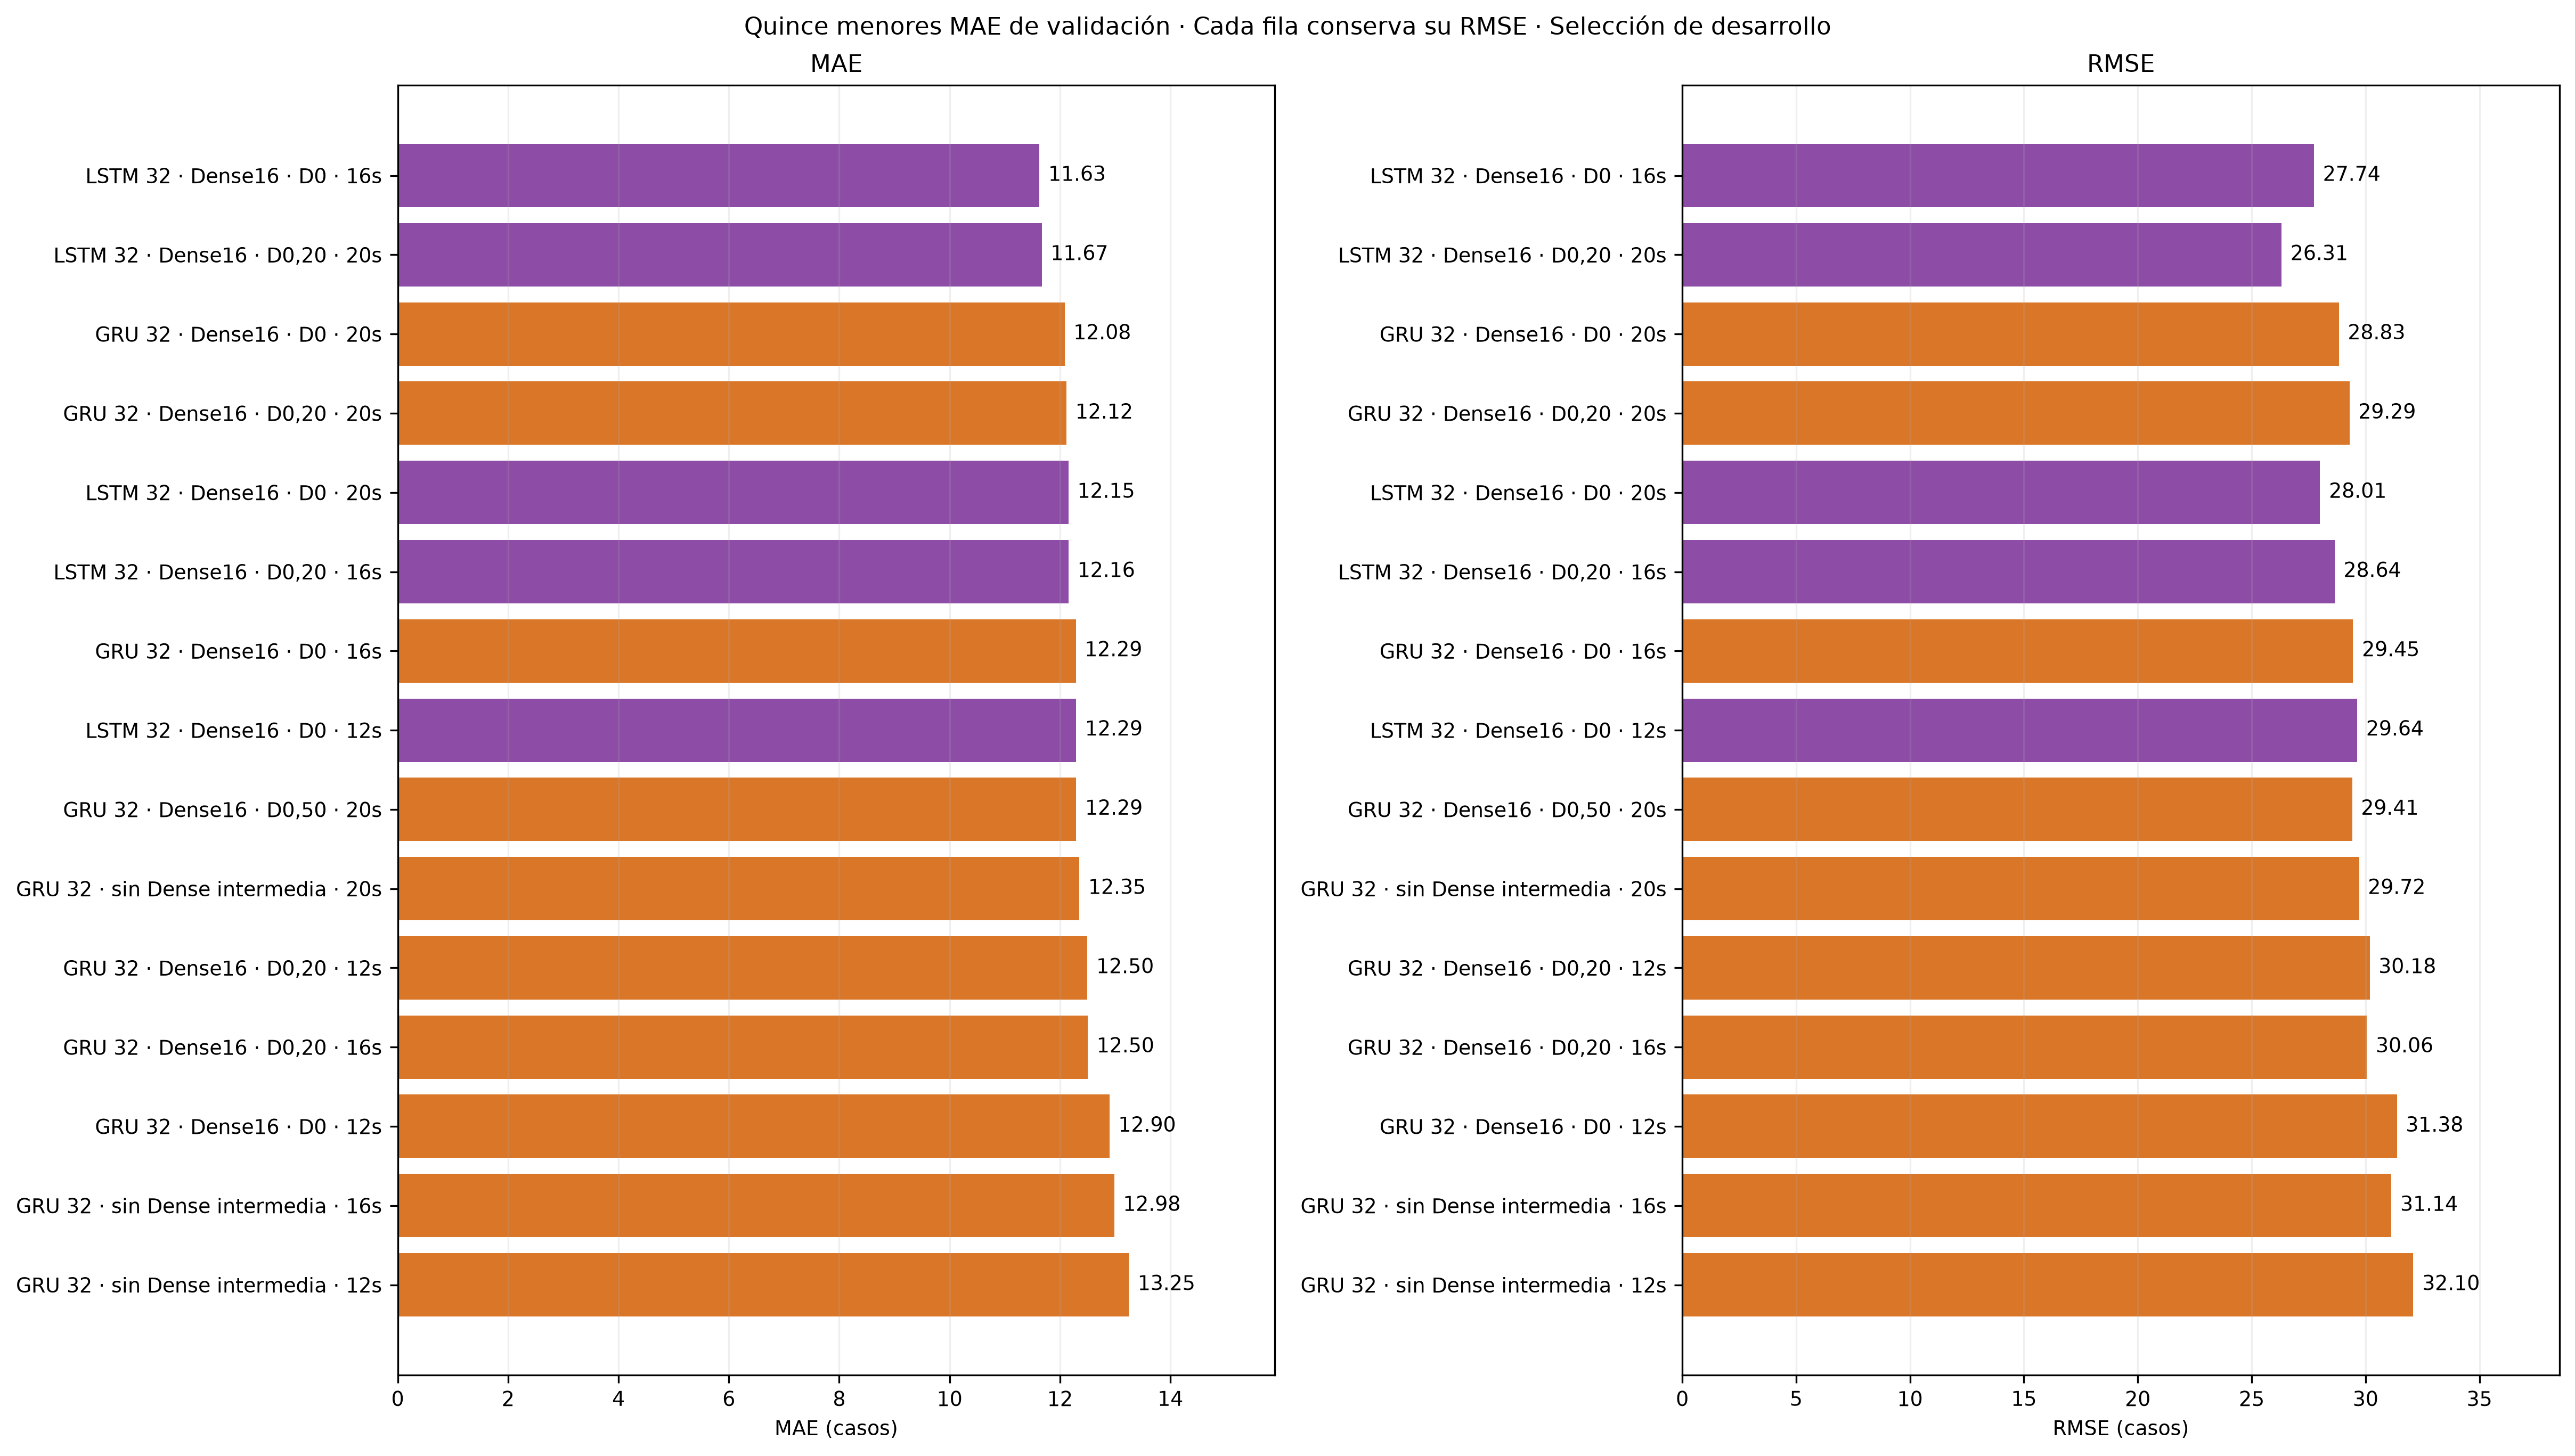

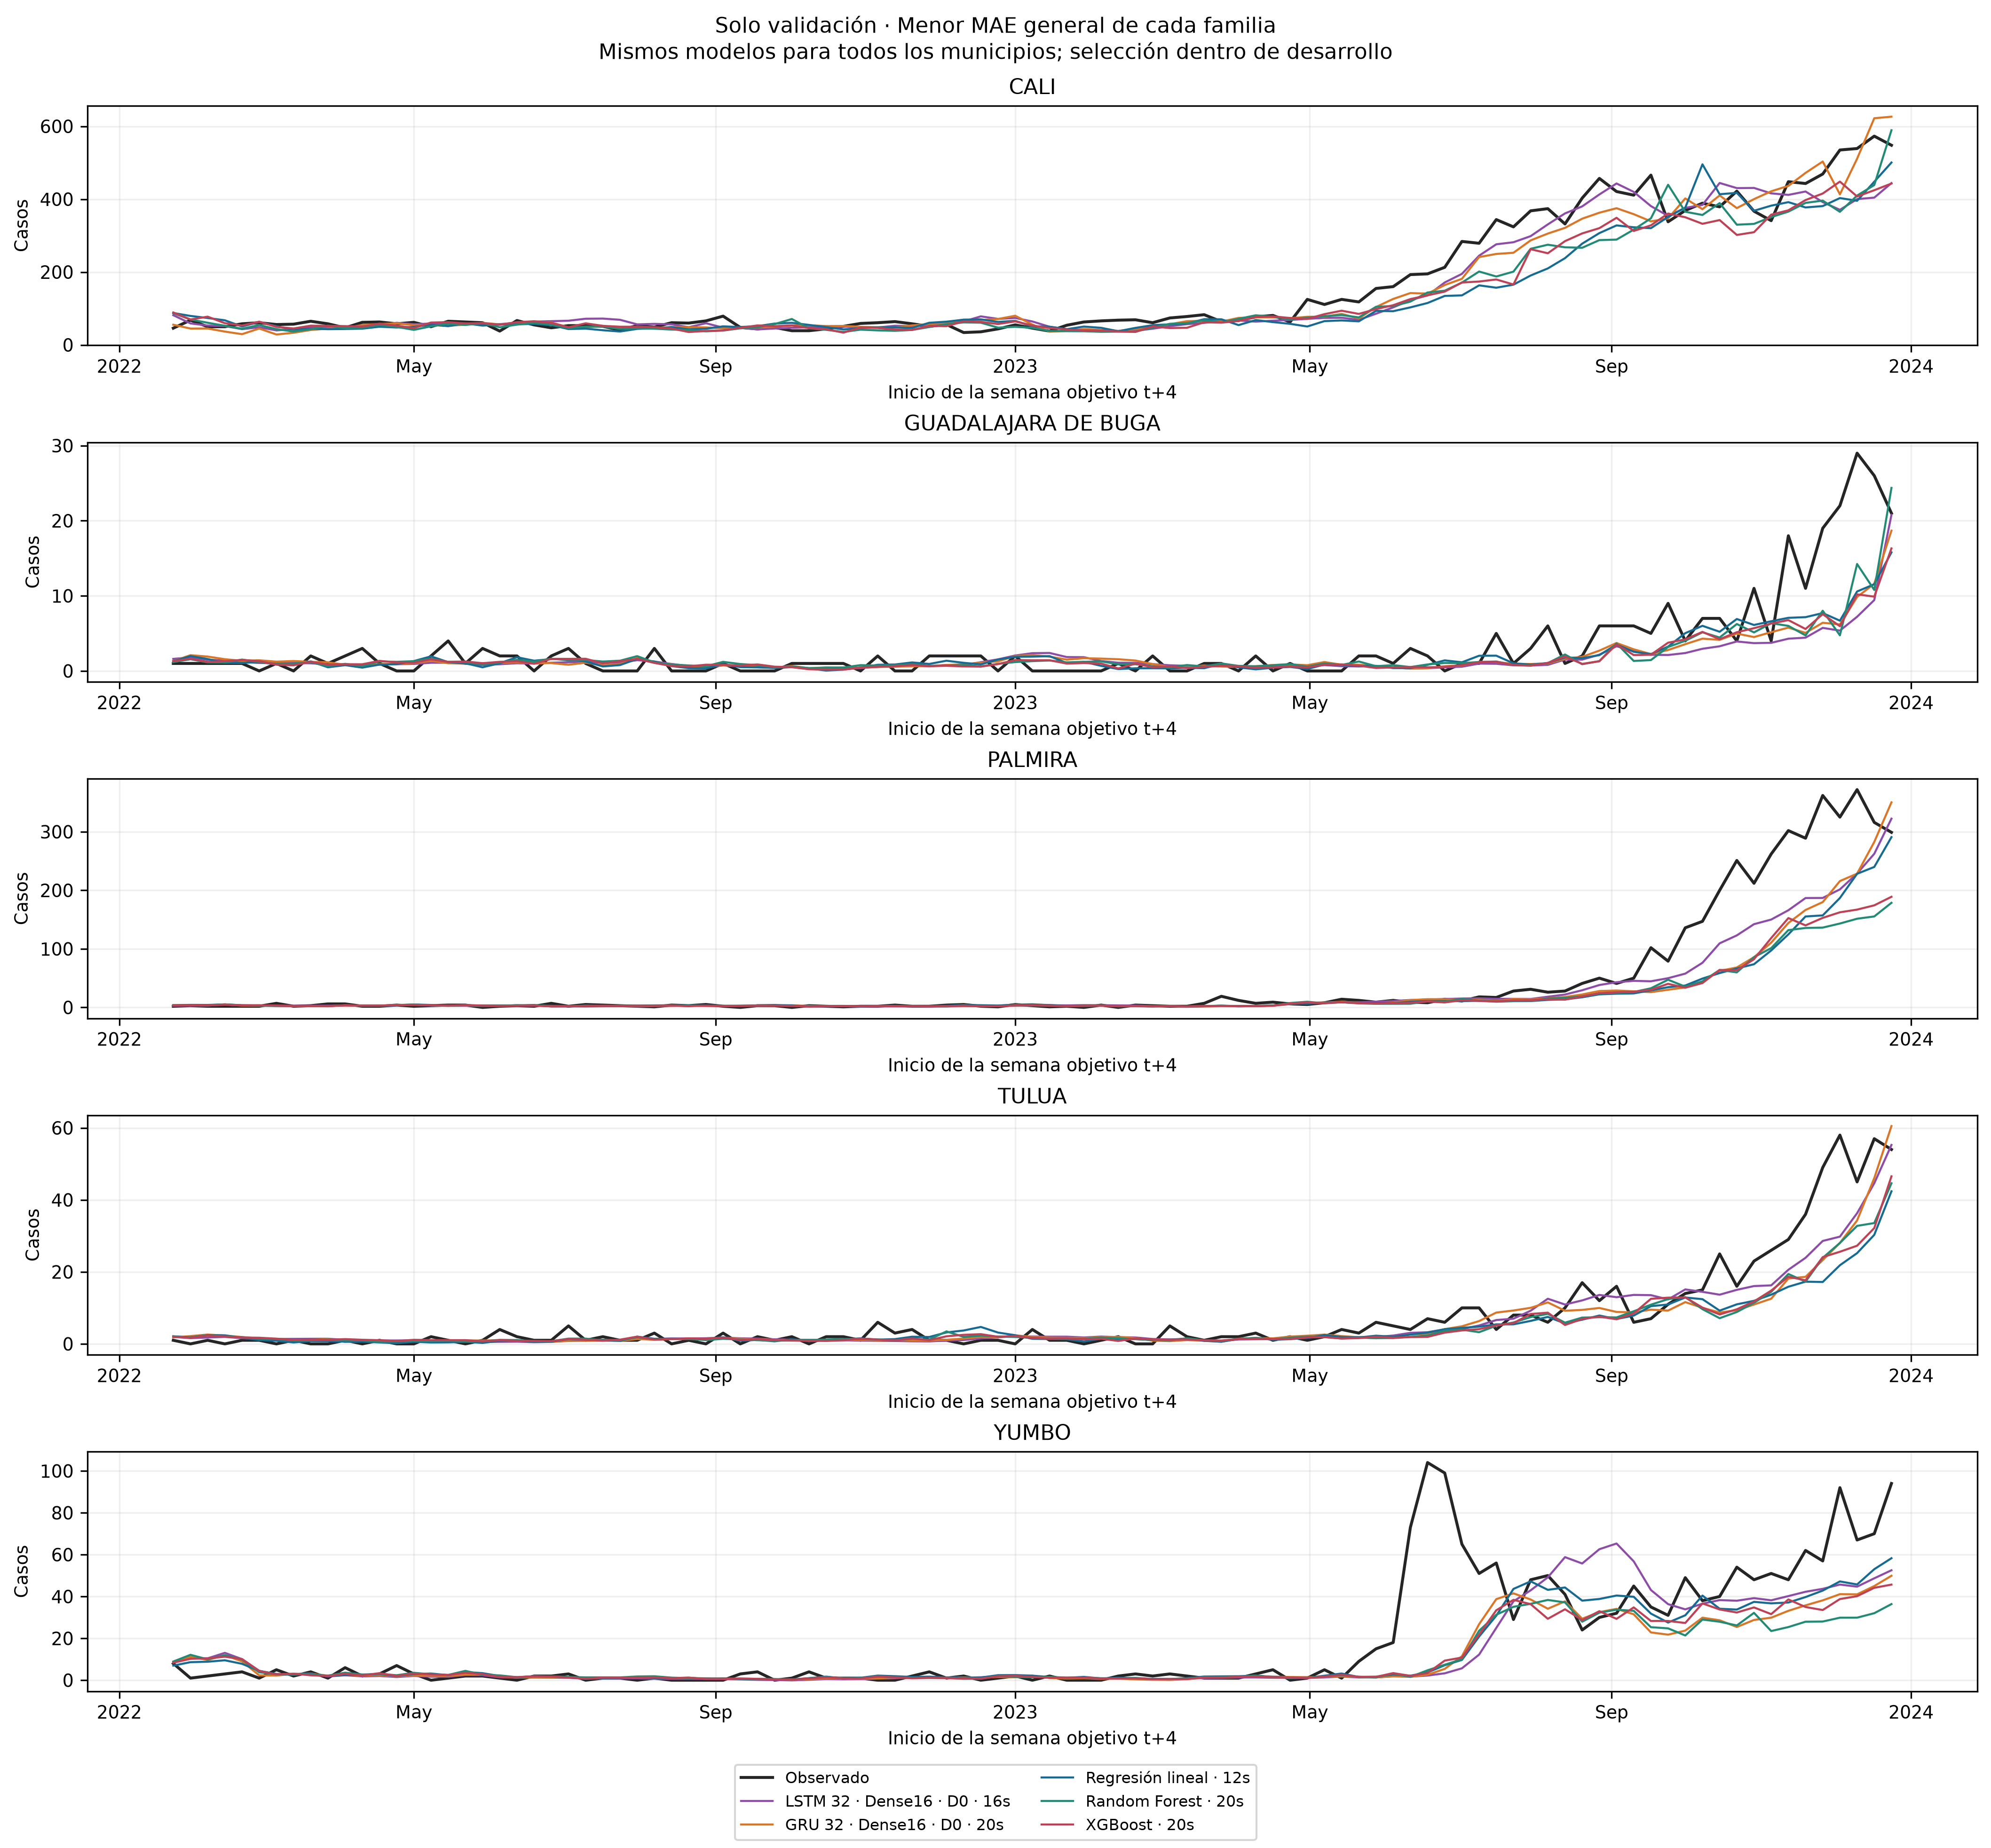

In [37]:
display(ranking_validacion[['MODELO','HISTORIA','N','MAE','RMSE','RMSE_PROMEDIO_MUNICIPAL','PRONOSTICOS_NEGATIVOS']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','RMSE_PROMEDIO_MUNICIPAL':'{:.3f}'}).hide(axis='index'))
mejores_por_familia_historia = resumir_validacion(ranking_validacion)
display(mejores_por_familia_historia.style.format({'MIN_MAE':'{:.3f}','MIN_RMSE':'{:.3f}'}).hide(axis='index'))
for archivo in ['07_matriz_arquitecturas_historias','08_ranking_validacion_top15','09_series_solo_validacion']:
    display(Image(filename=str(RUTA_DESARROLLO/'figuras'/f'{archivo}.png')))


### 18.1. Revisar los errores por municipio

La tabla presenta los errores municipales de las seis configuraciones con menor MAE general. Permite ver diferencias que el promedio puede ocultar, sin elegir un modelo distinto para cada ciudad. El detalle de las 50 configuraciones está en `tablas/metricas_municipales.csv`, dentro de la carpeta de esta ejecución.


In [38]:
ids_resumidos = ranking_validacion.head(6)['ID']
detalle_municipal = metricas_municipales_desarrollo.loc[
    metricas_municipales_desarrollo['CONJUNTO'].eq('validation')&metricas_municipales_desarrollo['ID'].isin(ids_resumidos)]
display(detalle_municipal[['MODELO','MUNICIPIO','MAE','RMSE','SESGO_MEDIO']].style.format(
    {'MAE':'{:.3f}','RMSE':'{:.3f}','SESGO_MEDIO':'{:.3f}'}).hide(axis='index'))


MODELO,MUNICIPIO,MAE,RMSE,SESGO_MEDIO
LSTM 32 · Dense16 · D0 · 16s,CALI,28.144,42.820,-14.839
LSTM 32 · Dense16 · D0 · 16s,GUADALAJARA DE BUGA,2.084,4.169,-1.390
LSTM 32 · Dense16 · D0 · 16s,PALMIRA,16.062,39.507,-14.421
LSTM 32 · Dense16 · D0 · 16s,TULUA,2.600,4.858,-1.292
LSTM 32 · Dense16 · D0 · 16s,YUMBO,9.246,20.291,-5.086
"LSTM 32 · Dense16 · D0,20 · 16s",CALI,32.499,47.595,-19.202
"LSTM 32 · Dense16 · D0,20 · 16s",GUADALAJARA DE BUGA,1.868,3.224,-1.102
"LSTM 32 · Dense16 · D0,20 · 16s",PALMIRA,15.886,38.021,-10.045
"LSTM 32 · Dense16 · D0,20 · 16s",TULUA,2.576,4.676,-1.205
"LSTM 32 · Dense16 · D0,20 · 16s",YUMBO,7.948,18.956,-6.000


## 19. Discutir los resultados y elegir un candidato

Usamos el **menor MAE de validación en casos** como criterio principal. Revisamos también cuál tiene el menor RMSE, porque una configuración puede acertar mejor en promedio y otra reducir más los errores grandes.

El análisis siguiente se calcula a partir de las métricas guardadas. La elección sigue siendo provisional: comparamos muchas configuraciones sobre los mismos años y con una sola semilla. Una diferencia pequeña no basta para afirmar que un modelo será mejor en otros periodos.


In [39]:
discusion_desarrollo, cambios_arquitecturas = conclusiones_desarrollo(
    ranking_validacion,metricas_municipales_desarrollo,catalogo_entrenado)
display(Markdown(discusion_desarrollo))
display(cambios_arquitecturas.style.format({'MAE_REFERENCIA':'{:.3f}','MAE_VARIANTE':'{:.3f}',
    'MEJORA_MAE_PCT':'{:.2f}','CAMBIO_RMSE':'{:+.3f}'}).hide(axis='index'))
print('Candidato provisional:',seleccion_validacion['ID_ELEGIDO'])
print('Resultados de desarrollo:',RUTA_DESARROLLO)


**Con qué modelo seguiríamos por ahora.** El menor MAE de las 50 configuraciones corresponde a **LSTM 32 · Dense16 · D0 · 16s**: **11.627 casos**, con RMSE de 27.738. Elegimos provisionalmente ese modelo porque fijamos MAE como criterio principal. Si miramos solo RMSE, el mínimo es de **LSTM 32 · Dense16 · D0,20 · 20s** (26.314). Ambos errores están expresados en casos de la semana t+4.

**LSTM, GRU y la cantidad de historia.** LSTM: LSTM 32 · Dense16 · D0 · 16s (MAE 11.627, RMSE 27.738); GRU: GRU 32 · Dense16 · D0 · 20s (MAE 12.083, RMSE 28.829). Todas las historias tuvieron los mismos 3.800 ejemplos de entrenamiento y 505 objetivos de validación. Por tanto, la comparación cambia la información disponible dentro de cada ventana, sin añadir más fechas de entrenamiento a una opción.

**Qué aportaron Dropout y las capas.** Añadir únicamente Dropout redujo el MAE frente a la referencia en **2 de las 12 variantes**. Las estructuras de dos o tres capas con Dropout lo redujeron en **0 de 12**, y quitar la Dense intermedia, en **0 de 6**. Cada variante se contrasta con su propia familia e historia. Las redes profundas cambian a la vez capas y Dropout: estos resultados no aíslan el efecto de cada cambio. La tabla siguiente permite revisar dónde mejoró o empeoró cada estructura; mejora porcentual positiva significa menor MAE y cambio de RMSE negativo significa menor RMSE.

**Cómo cambia el error entre municipios.** En el candidato provisional, el MAE municipal va de 2.084 en GUADALAJARA DE BUGA a 28.144 en CALI. Son errores en cantidades de casos y los municipios tienen volúmenes distintos; esa diferencia no demuestra por sí sola que el modelo funcione proporcionalmente mejor en uno. Se conserva un mismo modelo global, elegido por el MAE general, para los cinco municipios.

**Hasta dónde podemos concluir.** Estas diferencias describen una ejecución con una semilla y el mismo bloque de validación 2022–2023. Probar más configuraciones puede producir un mínimo optimista; además, las ventanas se solapan. Todavía hacen falta otros cortes cronológicos o semillas y referencias sencillas de persistencia o estacionales para revisar estabilidad. No se ha demostrado superioridad estadística, causalidad ni utilidad de una intervención sanitaria.

**El cierre queda pendiente.** Se mantuvieron los escaladores ajustados en entrenamiento y las predicciones continuas, incluidos los valores negativos que las tablas contabilizan. No se volvió a leer el test durante esta exploración. Como el bloque 2024–2025 ya se había observado antes, usarlo posteriormente tampoco constituirá una prueba ciega. La evaluación y su análisis final permanecen desactivados en el último punto del notebook mientras decidimos con qué configuración continuar.


FAMILIA,HISTORIA,RECETA,MAE_REFERENCIA,MAE_VARIANTE,MEJORA_MAE_PCT,CAMBIO_RMSE
LSTM,12,sin_dense,12.292,14.793,-20.34,+6.297
LSTM,12,drop20,12.292,13.834,-12.54,+5.237
LSTM,12,drop50,12.292,14.147,-15.08,+5.371
LSTM,12,dos_capas,12.292,14.194,-15.47,+5.882
LSTM,12,tres_capas,12.292,16.603,-35.07,+13.538
LSTM,16,sin_dense,11.627,14.156,-21.75,+5.447
LSTM,16,drop20,11.627,12.155,-4.54,+0.906
LSTM,16,drop50,11.627,13.563,-16.65,+5.656
LSTM,16,dos_capas,11.627,14.295,-22.95,+7.743
LSTM,16,tres_capas,11.627,16.633,-43.06,+15.468


Candidato provisional: lstm_referencia_v16
Resultados de desarrollo: ResultadosModelos\exploracion_temporal_validacion\ejecucion_291cbf82


### 19.1. Relacionar los resultados con los antecedentes

**Zhao et al. (2020)** compararon Random Forest con datos agrupados y modelos locales a escala departamental en Colombia. Utilizaron 12 semanas de historia y distintas anticipaciones. Su trabajo sirve como referencia para estudiar la cantidad de historia y el uso de información de varios lugares. Nuestro análisis es municipal y tiene un único objetivo, t+4, por lo que sus errores no son directamente comparables con los nuestros.

**Benedum et al. (2020)** estudiaron tanto el pronóstico de casos como la clasificación de semanas de brote, con 26 semanas de historia y anticipaciones de 4 y 12 semanas. Evaluaron los modelos avanzando en el tiempo y reentrenándolos por año. Ese procedimiento ofrece una referencia para ampliar nuestro análisis con otros cortes cronológicos, además del bloque fijo de validación que usamos aquí.

**Schlesinger et al. (2024)** evaluaron EWARS-csd en 11 municipios colombianos, con clima y hospitalizaciones, y midieron su capacidad para anticipar brotes. Su objetivo y su modelo DLNM–INLA son distintos de nuestra regresión de casos. Esta diferencia importa al interpretar el alcance del trabajo: un error de pronóstico bajo no demuestra por sí solo que podamos detectar brotes.


### 19.2. Reconocer las limitaciones

La comparación tiene varias limitaciones que debemos considerar al interpretar los resultados:

- Los cinco municipios se eligieron por su volumen de casos en 2007–2023. Los errores representan esos municipios y esas cantidades, no tasas ajustadas por población ni resultados para todo el departamento.
- Contamos registros según `ANO` y `SEMANA`, después de excluir filas sin `INI_SIN`. Las filas coincidentes se conservan, por lo que no se ha comprobado que cada una corresponda a un episodio único. También falta confirmar con el diccionario de vigilancia que las semanas de casos y clima tengan el mismo significado.
- Completar las semanas sin registros con cero supone que hubo cobertura de notificación. Los archivos no permiten distinguir siempre una ausencia real de casos de una falla de reporte.
- Suponemos que los casos y el clima hasta t estaban disponibles al emitir el pronóstico. No reconstruimos retrasos de notificación ni revisiones posteriores de los datos.
- No contamos con población, información entomológica, movilidad, serotipos o intervenciones. El análisis permite comparar predicciones, pero no identificar efectos causales del clima.
- La salida lineal puede producir valores negativos. Se conservan y contabilizan en las métricas; cualquier tratamiento distinto tendría que definirse y validarse antes de usar el modelo.
- Las ventanas se solapan y probamos varias configuraciones con una sola semilla sobre la misma validación. Faltan otros cortes temporales, semillas y referencias de persistencia o estacionales para estudiar la estabilidad. Tampoco se ha evaluado el beneficio de usar estos pronósticos en una intervención sanitaria.


## 20. Evaluar el modelo y realizar el análisis final

Este bloque queda al final y permanece **desactivado** mientras siga abierta la exploración: `EJECUTAR_EVALUACION_FINAL = False`.

Cuando se cierre la selección, recuperará el candidato elegido por MAE de validación y la mejor configuración de cada familia. Guardará esa elección antes de leer el conjunto de evaluación y aplicará los modelos sin volver a ajustar pesos ni escaladores. La comparación está preparada para 510 objetivos, 102 por municipio, con emisiones desde el cierre de validación del 30 de diciembre de 2023.

Aquí se generarán las métricas, las gráficas por municipio para entrenamiento, validación y evaluación, y el análisis final del candidato. Esa nueva evaluación todavía no se ha ejecutado.

El periodo 2024–2025 ya se consultó en etapas anteriores. Aunque ahora esté separado de la exploración, una nueva evaluación sobre él no será una prueba ciega. Para estudiar el desempeño en datos no utilizados en decisiones anteriores hará falta otro periodo o un protocolo temporal que mantenga esa separación.

Los resultados previos se conservan como antecedentes, fuera de las tablas de selección actuales:

- Evaluación anterior de LSTM y baselines.
- Comparación anterior con GRU y XGBoost.


In [40]:
EJECUTAR_EVALUACION_FINAL = False
if EJECUTAR_EVALUACION_FINAL:
    (predicciones_evaluacion_cierre,metricas_evaluacion_cierre,metricas_municipales_cierre,
     analisis_final_cierre,RUTA_EVALUACION_CIERRE) = evaluar_al_cierre(
        RUTA_DESARROLLO,datos_desarrollo,preprocesamiento_desarrollo,
        catalogo_entrenado,ranking_validacion,seleccion_validacion)
    display(metricas_evaluacion_cierre.style.format({'MAE':'{:.3f}','RMSE':'{:.3f}'}).hide(axis='index'))
    metricas_tres_conjuntos_cierre, figuras_finales = graficar_al_cierre(
        predicciones_desarrollo,predicciones_evaluacion_cierre,RUTA_EVALUACION_CIERRE)
    display(Markdown('### Análisis final al cierre\n\n'+analisis_final_cierre))
    print('Resultados del cierre:',RUTA_EVALUACION_CIERRE)
else:
    display(Markdown('**Evaluación desactivada.** La exploración actual usa únicamente train y validation. El candidato y las conclusiones de desarrollo son provisionales; el análisis final se actualizará aquí cuando se cierre la configuración.'))


**Evaluación desactivada.** La exploración actual usa únicamente train y validation. El candidato y las conclusiones de desarrollo son provisionales; el análisis final se actualizará aquí cuando se cierre la configuración.